# Training-Free Bayesianization (TFB) of the Binary Safety Classifier

This notebook implements [ADR 0002](../docs/adr/0002-tfb-uncertainty-for-safety-classification.md) for the binary classifier exported by `training_binary_classifier.ipynb`. It Bayesianizes the trained LoRA adapters without retraining, selects the posterior noise scale $\sigma_q$ on an anchor set, and evaluates the resulting Bayesian model average (BMA) and its uncertainty decomposition.

Notation follows the ADR. For each of the 48 adapted layers, $\mathbf{W}_0 \in \mathbb{R}^{m\times n}$ is the frozen weight, $\Delta\mathbf{W} = s\,\mathbf{B}\mathbf{A}$ with $\mathbf{B} \in \mathbb{R}^{m\times r}$, $\mathbf{A} \in \mathbb{R}^{r\times n}$ and $s = \alpha/r$, and $s\mathbf{B} = \mathbf{U}\,\mathrm{diag}(\mathbf{d})\,\mathbf{V}^\top$ is a compact SVD. The posterior sample is

$$\mathbf{W} = \mathbf{W}_0 + \mathbf{U}\big(\mathbf{U}^\top\Delta\mathbf{W} + \mathbf{Z}\big), \qquad Z_{ij} \sim \mathcal{N}(0, \sigma_q^2),$$

whose covariance is $\mathbf{I}_n \otimes \sigma_q^2\,\mathbf{U}\mathbf{U}^\top$. With $N$ posterior samples giving per-sample probabilities $p_n$ and mean $\bar p$, and $\mathcal{H}_b$ the binary entropy:

$$\mathrm{TU} = \mathcal{H}_b(\bar p), \qquad \mathrm{AU} = \tfrac{1}{N}\textstyle\sum_n \mathcal{H}_b(p_n), \qquad \mathrm{EU} = \mathrm{TU} - \mathrm{AU}.$$

All model outputs are stored as per-sample logits of shape `[N, D, K]` ($D$ examples, $K$ outputs; $K = 1$ here), so the posterior, search, and decomposition code applies unchanged to the multi-label models.

The final section adds the optional phase-2 posterior of ADR Decision 2, which also perturbs the weight matrices of the feed-forward head, and compares it with the LoRA-only posterior.

In [1]:
from __future__ import annotations

import json
import math
from collections import OrderedDict
from collections.abc import Callable, Iterator
from contextlib import contextmanager
from dataclasses import dataclass
from enum import StrEnum
from pathlib import Path
from typing import Any, Literal

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import Dataset as HFDataset
from datasets import DatasetDict
from datasets import load_dataset
from peft import PeftModel
from peft.tuners.lora import LoraLayer
from scipy.stats import rankdata
from torch import Tensor
from torch.func import functional_call
from torch.utils.data import DataLoader
from transformers import AutoModel, AutoTokenizer

# ---------------------------------------------------------------------------
# Constants
# ---------------------------------------------------------------------------

# Export written by training_binary_classifier.ipynb (adapter/, head.pt, config.json).
CHECKPOINT_DIR = Path("../outputs/binary_classifier/me5s_lora_binary/best")
RESULTS_DIR = CHECKPOINT_DIR.parent / "uncertainty"

BATCH_SIZE = 128

# Posterior samples used by the sigma search (ADR Decision 3) and by every
# evaluation (ADR Decision 4), and the sample counts swept in the sensitivity study.
# Samples are drawn in antithetic pairs, so every count must be even.
N_SEARCH_SAMPLES = 10
N_EVAL_SAMPLES = 50
N_SWEEP = (2, 4, 10, 20, 50)

# Sigma search (ADR Decision 3): anchor size, relative NLL tolerance, the relative
# accuracy tolerance of the ablation, bracketing start, and search budget.
ANCHOR_SIZE = 500
EPSILON_REL = 0.003
ACCURACY_TOLERANCE_REL = 0.01
SIGMA_INIT = 1e-3
MAX_BRACKET_DOUBLINGS = 20
BISECTION_STEPS = 8

# Multiples of sigma_star evaluated in the sensitivity study.
SIGMA_GRID_FACTORS = (0.25, 0.5, 1.0, 2.0, 4.0)

# Phase-2 head noise (ADR Decision 2) draws from generators seeded at
# SEED + HEAD_SEED_OFFSET + k, far from the LoRA seeds SEED + k, so the head and
# LoRA noise are independent.
HEAD_SEED_OFFSET = 1_000_000

# Singular directions with d_i <= RANK_TOL * d_1 are dropped (ADR Decision 2).
RANK_TOL = 1e-4

ECE_BINS = 15

# Out-of-distribution corpora: number of texts kept and minimum characters per text.
OOD_SIZE = 1_000
OOD_MIN_CHARS = 20

# Aegis category that marks the non-unsafe "Needs Caution" annotation.
NEEDS_CAUTION = "Needs Caution"

SEED = 0

In [2]:
# ---------------------------------------------------------------------------
# Definitions copied verbatim from training_binary_classifier.ipynb. They must
# match the training notebook so the checkpoint and data splits rebuild exactly.
# ---------------------------------------------------------------------------


class AegisLabels(StrEnum):
    SAFE = "safe"
    UNSAFE = "unsafe"


class AegisKeys(StrEnum):
    PROMPT = "prompt"
    RESPONSE = "response"
    PROMPT_LABEL = "prompt_label"
    RESPONSE_LABEL = "response_label"
    VIOLATED_CATEGORIES = "violated_categories"
    PROMPT_LABEL_SOURCE = "prompt_label_source"


def average_pool(last_hidden_states: Tensor, non_padding_mask: Tensor) -> Tensor:
    """
    Mean-pool token hidden states over non-padded positions.

    :param last_hidden_states:  Shape ``(B, L, D)`` — one vector per token position.
    :param non_padding_mask:    Shape ``(B, L)`` — 1 for real tokens, 0 for padding.
    :return:                    Shape ``(B, D)`` — one dense embedding per input sequence.
    """
    # [B, L, D] — zero out padded positions so they do not contribute to the sum.
    b, l, d = last_hidden_states.shape
    last_hidden = last_hidden_states.masked_fill(~non_padding_mask.reshape(b, l, 1).bool(), 0.0)

    # [B, D] — divide the summed vectors by the count of real tokens per sequence.
    return last_hidden.sum(dim=1) / non_padding_mask.sum(dim=1).reshape(b, 1)


def make_collate_fn(
    tokenizer: Any,
    max_length: int = 512,
):
    """
    Return a DataLoader collate function that tokenizes raw Aegis prompts.

    Tokenization happens at collation time so that each batch is padded to its
    own maximum length rather than the global maximum.

    :param tokenizer:   A HuggingFace ``PreTrainedTokenizer``.
    :param max_length:  Maximum token length for truncation.
    :return:            A collate callable for :class:`DataLoader`.
    """

    def _collate(
        batch: list[dict[str, Any]],
    ) -> tuple[dict[str, Tensor], Tensor]:
        texts = [row[AegisKeys.PROMPT] for row in batch]

        # "unsafe" is the positive class: 1.0 for unsafe prompts, 0.0 for safe.
        unsafe_star = torch.tensor(
            [float(row[AegisKeys.PROMPT_LABEL] == AegisLabels.UNSAFE) for row in batch],
            dtype=torch.float32,
        )

        # Tokenize the batch of raw prompts in one call.
        batch_dict: dict[str, Tensor] = tokenizer(
            texts,
            max_length=max_length,
            padding=True,
            truncation=True,
            return_tensors="pt",
        )

        return batch_dict, unsafe_star

    return _collate


def filter_by_token_length(
    dataset: HFDataset,
    tokenizer: Any,
    max_length: int,
    size: int,
) -> HFDataset:
    """
    Keep the leading ``size`` records whose prompt fits within ``max_length`` tokens.

    Records are tokenized without truncation, so the length includes the special
    tokens the encoder actually sees. The whole split is scanned so ``size`` is
    saturated whenever enough short prompts exist; otherwise every qualifying
    record is returned and a warning is printed.

    :param dataset:     A full Aegis split.
    :param tokenizer:   A HuggingFace ``PreTrainedTokenizer``.
    :param max_length:  Maximum allowed token length (inclusive).
    :param size:        Number of records to keep.
    :return:            The first ``min(size, num_qualifying)`` qualifying records,
                        in their original order.
    """

    # A plain str (not the enum) keeps ``_fits`` picklable, so datasets can cache the filter.
    prompt_key = AegisKeys.PROMPT.value

    def _fits(batch: dict[str, list[Any]]) -> list[bool]:
        input_ids = tokenizer(batch[prompt_key], truncation=False, verbose=False)["input_ids"]
        return [len(ids) <= max_length for ids in input_ids]

    qualifying = dataset.filter(_fits, batched=True)
    if len(qualifying) < size:
        print(
            f"Warning: only {len(qualifying)} of {len(dataset)} records fit within "
            f"{max_length} tokens; requested {size}."
        )
    return qualifying.select(range(min(size, len(qualifying))))


def label_counts(dataset: HFDataset) -> tuple[int, int]:
    """
    Count the safe and unsafe prompts in an Aegis split.

    :param dataset: An Aegis split (or subset of one).
    :return:        ``(num_safe, num_unsafe)``.
    """
    labels = list(dataset[AegisKeys.PROMPT_LABEL])
    return labels.count(AegisLabels.SAFE), labels.count(AegisLabels.UNSAFE)



class BinaryFFN(nn.Module):
    """
    Feed-forward head that maps a pooled embedding to a safety classification.

    :param num_layers:      Total number of linear layers (must be >= 2).
    :param input_dim:       Dimensionality of the pooled embedding input.
    :param hidden_dim:      Width of the hidden layers.
    :param weight_init:     Initialization strategy for hidden layers.
    """

    # Number of raw scalar outputs.
    NUM_RAW_OUTPUTS: int = 1

    def __init__(
        self,
        num_layers: int,
        input_dim: int,
        hidden_dim: int,
        weight_init: Literal["x_uniform", "x_normal", "zeros"] = "x_uniform",
    ) -> None:
        super().__init__()
        assert num_layers >= 2, "Need at least an input layer and an output layer."
        assert hidden_dim > 0

        # Select the weight initialization function for hidden layers.
        match weight_init:
            case "x_uniform":
                weight_init_fn = nn.init.xavier_uniform_
            case "x_normal":
                weight_init_fn = nn.init.xavier_normal_
            case "zeros":
                weight_init_fn = nn.init.zeros_
            case _:
                raise ValueError(f"Unknown weight_init: {weight_init!r}")

        # Construct the layer stack: Linear -> [GELU -> Linear] x (num_layers - 1).
        layers: list[tuple[str, nn.Module]] = [("00_Linear", nn.Linear(input_dim, hidden_dim))]
        for i in range(1, num_layers):
            if i < num_layers - 1:
                # Hidden layer: user-selected initialization.
                linear = nn.Linear(hidden_dim, hidden_dim)
                weight_init_fn(linear.weight)
            else:
                # Output layer: zero-initialized weights for a neutral start.
                linear = nn.Linear(hidden_dim, self.NUM_RAW_OUTPUTS)
                nn.init.zeros_(linear.weight)

            nn.init.zeros_(linear.bias)
            layers.extend(
                [
                    (f"{i:02d}_GELU", nn.GELU()),
                    (f"{i:02d}_Linear", linear),
                ]
            )

        self.model = nn.Sequential(OrderedDict(layers))

    def forward(self, x: Tensor) -> Tensor:
        """
        Map a pooled embedding to an unsafe-class logit.

        :param x:   Pooled embedding of shape ``(B, input_dim)``.
        :return:    Logits of shape ``(B,)``.
        """
        # [B, input_dim] -> [B, 1]
        raw = self.model(x)
        # [B, 1] -> [B,]
        return raw.squeeze(1)


class SafetyModel(nn.Module):
    """
    End-to-end safety task-head: LoRA-adapted ME5-small encoder followed
    by a mean-pool and a feed-forward binary classification head.

    :param embedding_model:     A PEFT-wrapped HuggingFace encoder.
    :param ffn_model:           The :class:`BinaryFFN` head.

    """

    def __init__(
        self,
        embedding_model: nn.Module,
        ffn_model: BinaryFFN,
    ) -> None:
        super().__init__()
        self._embedding_model = embedding_model
        self._ffn_model = ffn_model


    def forward(
        self,
        batch_dict: dict[str, Tensor],
        return_attentions: bool = False,
    ) -> Tensor | tuple[Tensor, Tensor, Tensor]:
        """
        Encode the tokenized input and predict if the query is safe or not.

        :param batch_dict:          Tokenizer output dict with ``input_ids`` and
                                    ``attention_mask`` keys.
        :param return_attentions:   When True, also return the final encoder
                                    layer's attention tensor and the attention
                                    mask for heatmap visualization.
        :return:                    Unsafe-class logits of shape ``(B,)``; or,
                                    when ``return_attentions`` is set,
                                    ``(logits, last_layer_attn, attention_mask)``
                                    where ``last_layer_attn`` has shape
                                    ``[B, H, L, L]``.
        """
        # Request per-layer attention weights only when a heatmap is needed;
        # the extra tensors are avoided on the hot training path.
        encoder_kwargs = {"output_attentions": True} if return_attentions else {}

        # Run the LoRA-adapted encoder.
        # [B, L, 384] — one hidden vector per token position.
        emb_outputs = self._embedding_model(**batch_dict, **encoder_kwargs)

        # [B, 384] — mean-pool over non-padded tokens.
        emb_x = average_pool(emb_outputs.last_hidden_state, batch_dict["attention_mask"])

        # [B, 384] -> [B,]
        logits = self._ffn_model(emb_x)

        if not return_attentions:
            return logits

        # emb_outputs.attentions is a tuple of [B, H, L, L] tensors, one per
        # encoder layer. The final layer's map is aggregated downstream into
        # per-token salience for the attention heatmap.
        last_layer_attn = emb_outputs.attentions[-1]
        return logits, last_layer_attn, batch_dict["attention_mask"]


# Aegis stores prompts that could not be released verbatim as this placeholder.
REDACTED_PROMPT = "REDACTED"

# Official splits in leakage-removal order: a prompt that occurs in several splits
# is kept only in the last of them, so no evaluation prompt is seen in training.
AEGIS_SPLITS = ("train", "validation", "test")


def parse_categories(raw: str | None) -> list[str]:
    """
    Split an Aegis ``violated_categories`` string into category names.

    :param raw: Comma-separated categories; ``None`` or empty means none.
    :return:    Stripped category names in their original order.
    """
    return [category.strip() for category in (raw or "").split(",") if category.strip()]


def clean_aegis_splits(
    dataset_dict: DatasetDict,
    tokenizer: Any,
    max_length: int,
) -> dict[str, HFDataset]:
    """
    Build deduplicated, leakage-free prompt splits that fit the token budget.

    Aegis pairs one prompt with several responses, so a prompt can repeat within a
    split and across splits. Each split is cleaned in five steps:

    1. Drop ``REDACTED`` placeholder prompts, whose text cannot support any label.
    2. Drop prompts longer than ``max_length`` tokens (special tokens included), so
       the collate function never truncates.
    3. Merge repeated prompts into one record whose categories are the union over
       the repeats in first-seen order; ``violated_categories`` is already a union
       over annotators, so the union keeps its meaning.
    4. Drop prompts whose repeats disagree on ``prompt_label``.
    5. Drop prompts that also occur in a later split (train, validation, test).

    :param dataset_dict:    The Aegis splits ``train``, ``validation``, and ``test``.
    :param tokenizer:       A HuggingFace ``PreTrainedTokenizer``.
    :param max_length:      Maximum allowed token length (inclusive).
    :return:                Split name to a dataset with ``prompt``, ``prompt_label``,
                            and ``violated_categories`` columns, in first-seen order.
    """
    prompt_key = AegisKeys.PROMPT.value
    label_key = AegisKeys.PROMPT_LABEL.value
    categories_key = AegisKeys.VIOLATED_CATEGORIES.value

    # Steps 1-3: group each split's in-budget, non-redacted records by exact prompt,
    # collecting every label seen and the union of categories.
    grouped: dict[str, dict[str, tuple[set[str], list[str]]]] = {}
    raw_sizes: dict[str, int] = {}
    for split in AEGIS_SPLITS:
        dataset = dataset_dict[split]
        prompts = list(dataset[prompt_key])
        labels = list(dataset[label_key])
        raw_categories = list(dataset[categories_key])
        input_ids = tokenizer(prompts, truncation=False, verbose=False)["input_ids"]
        raw_sizes[split] = len(prompts)

        groups: dict[str, tuple[set[str], list[str]]] = {}
        for prompt, label, raw, ids in zip(prompts, labels, raw_categories, input_ids, strict=True):
            if len(ids) > max_length or prompt.strip().upper() == REDACTED_PROMPT:
                continue
            seen_labels, merged = groups.setdefault(prompt, (set(), []))
            seen_labels.add(label)
            for category in parse_categories(raw):
                if category not in merged:
                    merged.append(category)
        grouped[split] = groups

    # Steps 4-5: drop label conflicts and prompts that reappear in a later split.
    cleaned: dict[str, HFDataset] = {}
    print(f"{'split':<12}{'records':>9}{'unique fit':>12}{'conflicts':>11}{'leaked':>8}{'kept':>8}")
    for position, split in enumerate(AEGIS_SPLITS):
        later_prompts: set[str] = set().union(*(grouped[s] for s in AEGIS_SPLITS[position + 1:]))
        records: dict[str, list[str]] = {prompt_key: [], label_key: [], categories_key: []}
        num_conflicts = 0
        num_leaked = 0
        for prompt, (seen_labels, merged) in grouped[split].items():
            if len(seen_labels) > 1:
                num_conflicts += 1
                continue
            if prompt in later_prompts:
                num_leaked += 1
                continue
            records[prompt_key].append(prompt)
            records[label_key].append(next(iter(seen_labels)))
            records[categories_key].append(", ".join(merged))
        cleaned[split] = HFDataset.from_dict(records)
        print(
            f"{split:<12}{raw_sizes[split]:>9}{len(grouped[split]):>12}{num_conflicts:>11}"
            f"{num_leaked:>8}{len(cleaned[split]):>8}"
        )
    return cleaned


def take_leading(dataset: HFDataset, size: int | None) -> HFDataset:
    """
    Keep the first ``size`` records of a cleaned split, or all of them for ``None``.

    :param dataset: A split returned by :func:`clean_aegis_splits`.
    :param size:    Number of records to keep; ``None`` keeps every record.
    :return:        The leading records, in their original order.
    """
    if size is None:
        return dataset
    if size > len(dataset):
        print(f"Warning: only {len(dataset)} cleaned records available; requested {size}.")
    return dataset.select(range(min(size, len(dataset))))


In [3]:
# ---------------------------------------------------------------------------
# Rebuild the trained model and the exact data splits from the export.
# ---------------------------------------------------------------------------

config = json.loads((CHECKPOINT_DIR / "config.json").read_text())
MAX_LEN = config["max_len"]
UNSAFE_THRESHOLD = config["unsafe_threshold"]
print(f"Checkpoint from epoch {config['epoch']}, val metrics: {config['val_metrics']}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tokenizer = AutoTokenizer.from_pretrained(config["model_id"])

# No attention maps are needed here, so the fused SDPA kernel replaces the eager
# implementation used for training-time heatmaps; the weights are identical.
base_model = AutoModel.from_pretrained(config["model_id"], attn_implementation="sdpa")
lora_model = PeftModel.from_pretrained(base_model, CHECKPOINT_DIR / "adapter")

ffn = BinaryFFN(
    num_layers=config["head"]["num_layers"],
    input_dim=config["hidden_dim"],
    hidden_dim=config["head"]["hidden_dim"],
    weight_init=config["head"]["weight_init"],
)
ffn.load_state_dict(torch.load(CHECKPOINT_DIR / "head.pt", map_location="cpu"))

# Evaluation mode throughout: LoRA dropout must not add a second source of noise.
safety_model = SafetyModel(lora_model, ffn).to(device).eval()

collate_fn = make_collate_fn(tokenizer, max_length=MAX_LEN)
# Exports from before the cleaning pipeline used different splits, which this
# notebook can no longer rebuild.
if not config.get("clean_splits", False):
    raise ValueError(f"{CHECKPOINT_DIR} predates clean_aegis_splits; retrain and re-export the model")
aegis_dataset = load_dataset(config["dataset_id"])
cleaned_splits = clean_aegis_splits(aegis_dataset, tokenizer, MAX_LEN)
train_dataset = take_leading(cleaned_splits["train"], config["subset_size"])
val_dataset = take_leading(cleaned_splits["validation"], config["val_size"])
test_dataset = take_leading(cleaned_splits["test"], config["test_size"])


def make_loader(dataset: HFDataset) -> DataLoader:
    """
    Build a deterministic (unshuffled) evaluation loader.

    :param dataset: Records with ``prompt`` and ``prompt_label`` columns.
    :return:        A loader yielding ``(batch_dict, unsafe_star)``.
    """
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)


def unsafe_targets(dataset: HFDataset) -> Tensor:
    """
    Ground-truth unsafe indicators in dataset order.

    :param dataset: An Aegis split (or subset of one).
    :return:        Float targets of shape ``[D, 1]`` (1.0 = unsafe).
    """
    labels = list(dataset[AegisKeys.PROMPT_LABEL])
    return torch.tensor([[float(label == AegisLabels.UNSAFE)] for label in labels])


train_loader = make_loader(train_dataset)
test_loader = make_loader(test_dataset)
y_train = unsafe_targets(train_dataset)
y_test = unsafe_targets(test_dataset)
print(f"train {len(train_dataset)} | val {len(val_dataset)} | test {len(test_dataset)}")

Checkpoint from epoch 10, val metrics: {'loss': 0.32818452920764685, 'accuracy': 0.8553149606299213, 'precision': 0.8797909407665505, 'recall': 0.8662092624356775, 'f1': 0.8729472774416595, 'tp': 505, 'fp': 69, 'fn': 78, 'tn': 364}


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

split         records  unique fit  conflicts  leaked    kept
train           30007       19524        165     309   19050
validation       1445        1025          0       9    1016
test             1964        1711          1       0    1710
train 19050 | val 1016 | test 1710


## TFB reparameterization

Every adapted layer is rewritten in the orthonormal parameterization of ADR Decision 2: the $\mathbf{B}$-side factor becomes $\mathbf{U}$ (stored as $\mathbf{U}/s$ because PEFT multiplies by $s$) and the $\mathbf{A}$-side factor becomes the mean $\mathbf{A}'' = \mathbf{U}^\top\Delta\mathbf{W}$. Directions with $d_i \le \tau d_1$ are zeroed. The update $\Delta\mathbf{W}$, and therefore every prediction, is unchanged; the checks below assert this before any noise is added.

48 layers reparameterized
max |s B'' A'' - dW| = 1.99e-07, max logit change = 1.24e-05
effective ranks: min 16, max 16 (of 16)


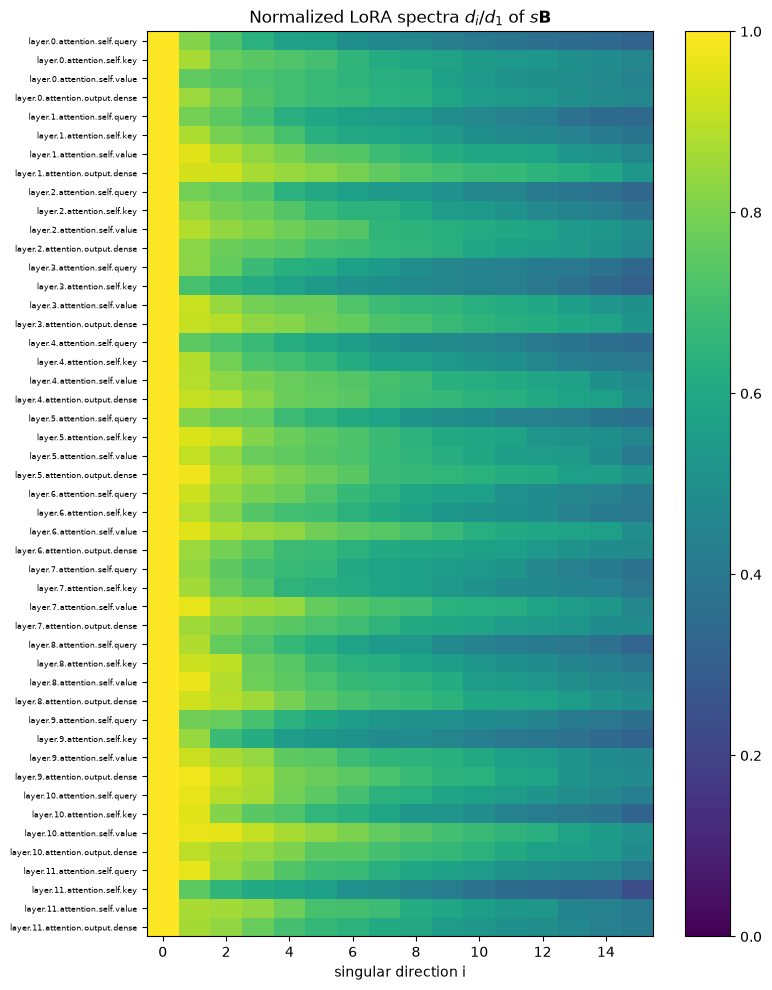

In [4]:
def predict_logits(model: nn.Module, loader: DataLoader) -> Tensor:
    """
    Run one deterministic pass of the model with its current weights.

    :param model:   The safety model (in evaluation mode).
    :param loader:  Loader yielding ``(batch_dict, targets)``.
    :return:        Logits of shape ``[D, K]`` on the CPU.
    """
    outputs: list[Tensor] = []
    with torch.no_grad():
        for batch_dict, _ in loader:
            batch_dict = {k: v.to(device) for k, v in batch_dict.items()}
            logits = model(batch_dict)
            outputs.append(logits.reshape(logits.shape[0], -1).float().cpu())
    return torch.cat(outputs)


@dataclass
class TFBLayer:
    """
    One LoRA layer in TFB's orthonormal parameterization.

    :param name:        Module path inside the PEFT model.
    :param module:      The PEFT ``LoraLayer``.
    :param a_mean:      Posterior mean ``A'' = U^T dW`` of the A-side factor, ``[r, n]``.
    :param keep:        Retained singular directions, ``[r]`` (float 0/1 mask).
    :param spectrum:    Normalized singular values ``d / d_1``, ``[r]``.
    :param original_a:  Trained ``lora_A`` weight, ``[r, n]``.
    :param original_b:  Trained ``lora_B`` weight, ``[m, r]``.
    """

    name: str
    module: LoraLayer
    a_mean: Tensor
    keep: Tensor
    spectrum: Tensor
    original_a: Tensor
    original_b: Tensor


def reparameterize_lora(model: nn.Module, rank_tol: float) -> list[TFBLayer]:
    """
    Rewrite every LoRA layer as ``B'' = U / s`` and ``A'' = U^T dW`` in place.

    :param model:       A model containing PEFT ``LoraLayer`` modules.
    :param rank_tol:    Relative singular-value threshold below which directions are dropped.
    :return:            One :class:`TFBLayer` per adapted layer whose adapter is non-zero.
    """
    layers: list[TFBLayer] = []
    with torch.no_grad():
        for name, module in model.named_modules():
            if not isinstance(module, LoraLayer):
                continue
            lora_a = module.lora_A["default"].weight      # [r, n]
            lora_b = module.lora_B["default"].weight      # [m, r]
            scaling = module.scaling["default"]

            # [m, r] @ [r, n] -> [m, n]
            delta_w = scaling * lora_b @ lora_a
            # U [m, r], d [r]; V is not needed in this parameterization.
            u, d, _ = torch.linalg.svd(scaling * lora_b, full_matrices=False)
            if d[0] <= 0:
                print(f"Skipping {name}: adapter update is zero")
                continue

            keep = (d > rank_tol * d[0]).to(lora_a.dtype)
            u = u * keep
            original_a, original_b = lora_a.clone(), lora_b.clone()
            a_mean = u.T @ delta_w                        # [r, n]
            lora_b.copy_(u / scaling)
            lora_a.copy_(a_mean)

            layers.append(
                TFBLayer(name, module, a_mean, keep, (d / d[0]).cpu(), original_a, original_b)
            )
    return layers


def restore_original_lora(layers: list[TFBLayer]) -> None:
    """
    Write the trained ``lora_A`` and ``lora_B`` weights back into every layer.

    :param layers:  Layers returned by :func:`reparameterize_lora`.
    """
    with torch.no_grad():
        for layer in layers:
            layer.module.lora_A["default"].weight.copy_(layer.original_a)
            layer.module.lora_B["default"].weight.copy_(layer.original_b)


# One test batch is enough to confirm the predictions are untouched.
check_loader = make_loader(test_dataset.select(range(min(BATCH_SIZE, len(test_dataset)))))
logits_before = predict_logits(safety_model, check_loader)

tfb_layers = reparameterize_lora(safety_model, RANK_TOL)

max_update_error = 0.0
for layer in tfb_layers:
    scaling = layer.module.scaling["default"]
    delta_w_original = scaling * layer.original_b @ layer.original_a
    delta_w_new = scaling * layer.module.lora_B["default"].weight @ layer.module.lora_A["default"].weight
    max_update_error = max(max_update_error, (delta_w_new - delta_w_original).abs().max().item())

logits_after = predict_logits(safety_model, check_loader)
max_logit_error = (logits_after - logits_before).abs().max().item()
print(f"{len(tfb_layers)} layers reparameterized")
print(f"max |s B'' A'' - dW| = {max_update_error:.2e}, max logit change = {max_logit_error:.2e}")
assert max_update_error < 1e-5 and max_logit_error < 1e-4

r_eff = [int(layer.keep.sum().item()) for layer in tfb_layers]
print(f"effective ranks: min {min(r_eff)}, max {max(r_eff)} (of {tfb_layers[0].keep.numel()})")

# [layers, r] heatmap of the normalized LoRA spectra.
spectra = torch.stack([layer.spectrum for layer in tfb_layers]).numpy()
fig, ax = plt.subplots(figsize=(8, 10))
image = ax.imshow(spectra, aspect="auto", cmap="viridis", vmin=0.0, vmax=1.0)
ax.set_yticks(range(len(tfb_layers)), [layer.name.split("encoder.")[-1] for layer in tfb_layers], fontsize=6)
ax.set_xlabel("singular direction i")
ax.set_title(r"Normalized LoRA spectra $d_i / d_1$ of $s\mathbf{B}$")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

In [5]:
# ---------------------------------------------------------------------------
# Posterior sampling with antithetic pairs and common random numbers.
# ---------------------------------------------------------------------------


class TFBPosterior:
    """
    Sampler for the low-rank isotropic Gaussian posterior over all TFB layers.

    Samples come in antithetic pairs: samples ``2k`` and ``2k + 1`` use the
    standard-normal matrices ``+Z_k`` and ``-Z_k``, where ``Z_k`` is drawn from a
    generator seeded with ``seed + k``. Each sample is still an exact draw from the
    posterior, but the average over a pair cancels every odd-order term of the
    Taylor expansion in ``sigma``, so the sample mean of ``Z`` is exactly zero and
    the search objective no longer carries a first-order Monte Carlo term.

    Every candidate ``sigma`` rescales the same matrices (common random numbers),
    which keeps the search objective smooth, and seeding per pair makes sample
    ``n`` identical no matter how many samples a given analysis requests.

    :param layers:  Layers returned by :func:`reparameterize_lora`.
    :param seed:    Base seed of the per-sample generators.
    """

    def __init__(self, layers: list[TFBLayer], seed: int) -> None:
        self.layers = layers
        self.seed = seed
        self._standard_normals: list[list[Tensor]] = []

    def standard_normals(self, n: int) -> list[Tensor]:
        """
        Per-layer standard-normal matrices of sample ``n``, each ``[r, n_in]``.

        :param n:   Sample index; ``n // 2`` selects the pair and ``n % 2`` the sign.
        :return:    One matrix per layer, on the layer's device.
        """
        pair, negate = divmod(n, 2)
        while len(self._standard_normals) <= pair:
            generator = torch.Generator().manual_seed(self.seed + len(self._standard_normals))
            self._standard_normals.append(
                [
                    torch.randn(layer.a_mean.shape, generator=generator).to(layer.a_mean)
                    for layer in self.layers
                ]
            )
        normals = self._standard_normals[pair]
        return [-z for z in normals] if negate else normals

    @contextmanager
    def sample(self, n: int, sigma: float) -> Iterator[None]:
        """
        Temporarily set every A-side factor to ``A'' + sigma * Z_n``.

        :param n:       Sample index.
        :param sigma:   Posterior noise scale ``sigma_q``.
        """
        try:
            with torch.no_grad():
                for layer, z in zip(self.layers, self.standard_normals(n), strict=True):
                    noise = sigma * layer.keep[:, None] * z
                    layer.module.lora_A["default"].weight.copy_(layer.a_mean + noise)
            yield
        finally:
            with torch.no_grad():
                for layer in self.layers:
                    layer.module.lora_A["default"].weight.copy_(layer.a_mean)


def collect_logits(
    model: nn.Module,
    posterior: TFBPosterior,
    loader: DataLoader,
    sigma: float,
    n_samples: int,
) -> Tensor:
    """
    Per-sample logits of the posterior predictive.

    The outer loop is over posterior samples, so the weights change once per
    sample rather than once per batch. ``sigma == 0`` is the deterministic model
    and returns a single sample.

    :param model:       The safety model (in evaluation mode).
    :param posterior:   The TFB posterior sampler.
    :param loader:      Loader yielding ``(batch_dict, targets)``.
    :param sigma:       Posterior noise scale ``sigma_q``.
    :param n_samples:   Number of posterior samples ``N``; must be even so that
                        every antithetic pair is complete.
    :return:            Logits of shape ``[N, D, K]`` on the CPU.
    """
    if sigma == 0.0:
        return predict_logits(model, loader).unsqueeze(0)
    if n_samples % 2:
        raise ValueError(f"n_samples must be even for antithetic pairs, got {n_samples}")

    samples: list[Tensor] = []
    for n in range(n_samples):
        with posterior.sample(n, sigma):
            samples.append(predict_logits(model, loader))
    return torch.stack(samples)


posterior = TFBPosterior(tfb_layers, SEED)

In [6]:
# ---------------------------------------------------------------------------
# Uncertainty decomposition and evaluation metrics (ADR Decisions 1 and 5).
# Every function accepts logits [N, D, K] and targets [D, K], so it applies to
# any number of Bernoulli outputs.
# ---------------------------------------------------------------------------

LN2 = math.log(2.0)


def binary_entropy(p: Tensor) -> Tensor:
    """
    Entropy of Bernoulli distributions, in nats.

    :param p:   Success probabilities of any shape.
    :return:    ``-p ln p - (1 - p) ln(1 - p)``, same shape as ``p``.
    """
    p = p.clamp(1e-7, 1.0 - 1e-7)
    return -(p * p.log() + (1.0 - p) * (1.0 - p).log())


@dataclass
class Decomposition:
    """
    Monte Carlo estimates of the predictive mean and the uncertainty decomposition.

    :param p_bar:       BMA probability, ``[D, K]``.
    :param total:       Total uncertainty ``H_b(p_bar)``, ``[D, K]``.
    :param aleatoric:   Aleatoric uncertainty ``mean_n H_b(p_n)``, ``[D, K]``.
    :param epistemic:   Epistemic uncertainty (BALD) ``total - aleatoric``, ``[D, K]``.
    :param logit_variance:  Unbiased sample variance of the logits across posterior
                            samples, ``[D, K]``; zero for a single sample.
    """

    p_bar: Tensor
    total: Tensor
    aleatoric: Tensor
    epistemic: Tensor
    logit_variance: Tensor


def decompose(logits: Tensor) -> Decomposition:
    """
    Decompose the predictive entropy of per-sample logits.

    :param logits:  Per-sample logits, ``[N, D, K]``.
    :return:        The :class:`Decomposition` of the BMA predictive.
    """
    probs = torch.sigmoid(logits)
    p_bar = probs.mean(dim=0)
    total = binary_entropy(p_bar)
    aleatoric = binary_entropy(probs).mean(dim=0)
    # Jensen's inequality guarantees total >= aleatoric; clamp float round-off.
    epistemic = (total - aleatoric).clamp_min(0.0)

    # Posterior disagreement on the logit itself, before the sigmoid; for small
    # noise EU ~= 0.5 * p_bar * (1 - p_bar) * Var[f], so this isolates the second factor.
    # [N, D, K] -> [D, K]
    logit_variance = logits.var(dim=0) if logits.shape[0] > 1 else torch.zeros_like(p_bar)
    return Decomposition(p_bar, total, aleatoric, epistemic, logit_variance)


def gibbs_nll(logits: Tensor, targets: Tensor, mask: Tensor | None = None) -> float:
    """
    Expected negative log-likelihood under the posterior (the sigma-search objective).

    :param logits:  Per-sample logits, ``[N, D, K]``.
    :param targets: Binary targets, ``[D, K]``.
    :param mask:    Optional ``[D, K]`` 0/1 mask of the outputs defined for each
                    example (the hook for masked multi-label heads).
    :return:        ``-E_q[ln p(y | x, theta)]``, summed over outputs and averaged
                    over samples and examples.
    """
    nll = F.binary_cross_entropy_with_logits(
        logits, targets.expand_as(logits), reduction="none"
    )
    if mask is not None:
        nll = nll * mask
    return nll.sum(dim=-1).mean().item()


def bma_nll(logits: Tensor, targets: Tensor) -> float:
    """
    Negative log-likelihood of the Bayesian model average.

    Computed as ``ln p_bar(y) = logsumexp_n ln p_n(y) - ln N`` for numerical stability.

    :param logits:  Per-sample logits, ``[N, D, K]``.
    :param targets: Binary targets, ``[D, K]``.
    :return:        ``-mean_D sum_K ln p_bar(y)``.
    """
    log_lik = -F.binary_cross_entropy_with_logits(
        logits, targets.expand_as(logits), reduction="none"
    )
    log_p_bar = torch.logsumexp(log_lik, dim=0) - math.log(logits.shape[0])
    return -log_p_bar.sum(dim=-1).mean().item()


def reliability_bins(
    p: Tensor, targets: Tensor, num_bins: int
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Bin binary predictions by confidence ``max(p, 1 - p)``.

    :param p:           Predicted probabilities, ``[D]``.
    :param targets:     Binary targets, ``[D]``.
    :param num_bins:    Number of equal-width bins over ``[0, 1]``.
    :return:            Per-bin mean confidence, accuracy, and count, each ``[num_bins]``.
    """
    confidence = torch.maximum(p, 1.0 - p).numpy()
    correct = ((p >= 0.5).float() == targets).float().numpy()
    bin_index = np.minimum((confidence * num_bins).astype(int), num_bins - 1)
    counts = np.bincount(bin_index, minlength=num_bins).astype(float)
    conf_sum = np.bincount(bin_index, weights=confidence, minlength=num_bins)
    acc_sum = np.bincount(bin_index, weights=correct, minlength=num_bins)
    safe_counts = np.maximum(counts, 1.0)
    return conf_sum / safe_counts, acc_sum / safe_counts, counts


def expected_calibration_error(p: Tensor, targets: Tensor, num_bins: int = ECE_BINS) -> float:
    """
    Expected calibration error of binary predictions.

    :param p:           Predicted probabilities, ``[D]``.
    :param targets:     Binary targets, ``[D]``.
    :param num_bins:    Number of equal-width confidence bins.
    :return:            ``sum_k |B_k| / D * |acc(B_k) - conf(B_k)|``.
    """
    conf, acc, counts = reliability_bins(p, targets, num_bins)
    return float(np.sum(counts / counts.sum() * np.abs(acc - conf)))


def auroc(scores: np.ndarray, positives: np.ndarray) -> float:
    """
    Area under the ROC curve via the Mann-Whitney U statistic (ties get mid-ranks).

    :param scores:      Scores where larger means "more likely positive", ``[D]``.
    :param positives:   Boolean positive indicators, ``[D]``.
    :return:            Probability that a random positive outscores a random negative.
    """
    num_pos = int(positives.sum())
    num_neg = len(positives) - num_pos
    if num_pos == 0 or num_neg == 0:
        return float("nan")
    ranks = rankdata(scores)
    return float((ranks[positives].sum() - num_pos * (num_pos + 1) / 2) / (num_pos * num_neg))


def auprc(scores: np.ndarray, positives: np.ndarray) -> float:
    """
    Area under the precision-recall curve as average precision.

    :param scores:      Scores where larger means "more likely positive", ``[D]``.
    :param positives:   Boolean positive indicators, ``[D]``.
    :return:            Mean precision at the rank of each positive.
    """
    order = np.argsort(-scores, kind="stable")
    hits = positives[order].astype(float)
    if hits.sum() == 0:
        return float("nan")
    precision_at_k = np.cumsum(hits) / np.arange(1, len(hits) + 1)
    return float((precision_at_k * hits).sum() / hits.sum())


# --- Sanity checks on synthetic inputs ---
check_generator = torch.Generator().manual_seed(SEED)
random_logits = 3.0 * torch.randn(10, 2_000, 1, generator=check_generator)
random_decomposition = decompose(random_logits)
assert (random_decomposition.epistemic >= 0).all()
assert (random_decomposition.epistemic <= random_decomposition.total + 1e-6).all()
assert (random_decomposition.total <= LN2 + 1e-6).all()
assert decompose(random_logits[:1].expand(10, -1, -1)).epistemic.max() < 1e-5
assert decompose(random_logits[:1].expand(10, -1, -1)).logit_variance.max() == 0.0
assert torch.allclose(random_decomposition.logit_variance, random_logits.var(dim=0))

calibrated_p = torch.rand(200_000, generator=check_generator)
calibrated_y = (torch.rand(200_000, generator=check_generator) < calibrated_p).float()
assert expected_calibration_error(calibrated_p, calibrated_y) < 0.01

separable = np.array([False] * 50 + [True] * 50)
assert auroc(np.arange(100.0), separable) == 1.0 and auroc(-np.arange(100.0), separable) == 0.0
assert auprc(np.arange(100.0), separable) == 1.0
print("Decomposition and metric sanity checks passed.")

Decomposition and metric sanity checks passed.


## Selecting $\sigma_q$

$\sigma_q^\star$ is the largest noise scale whose expected NLL on the anchor set stays within $\epsilon = 0.003\,\mathcal{L}(0)$ of the deterministic model (ADR Decision 3). The anchor set is 500 training records labeled with the deterministic model's own predictions; the likelihood is unweighted binary cross-entropy. The expectation uses `N_SEARCH_SAMPLES` posterior samples in antithetic pairs, so the Monte Carlo estimate of $\mathcal{L}(\sigma_q) - \mathcal{L}(0)$ has no first-order term in $\sigma_q$.

L(0) = 0.1415, epsilon = 4.25e-04, sigma_star = 3.070e-03


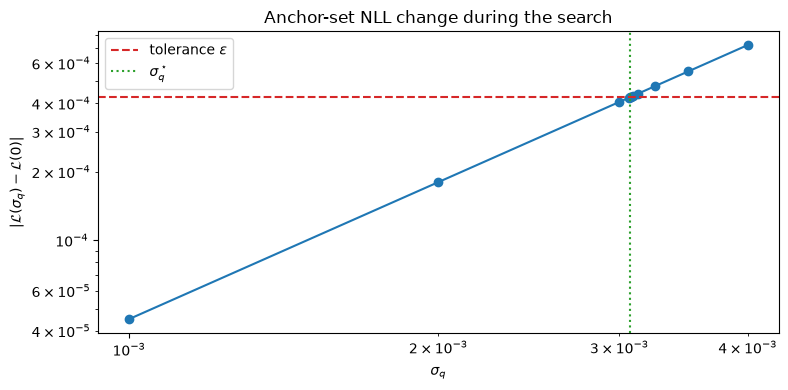

In [7]:
def search_sigma(
    objective: Callable[[float], float],
    tolerance: float,
) -> tuple[float, list[tuple[float, float]]]:
    """
    Largest sigma with ``|objective(sigma) - objective(0)| <= tolerance``.

    The bracket starts at ``SIGMA_INIT`` and doubles until the constraint is
    violated; bisection then refines the boundary.

    :param objective:   Anchor metric as a function of sigma.
    :param tolerance:   Allowed absolute change from ``objective(0)``.
    :return:            ``(sigma_star, trace)`` with every evaluated ``(sigma, value)``.
    """
    base = objective(0.0)
    trace = [(0.0, base)]

    def satisfies(sigma: float) -> bool:
        value = objective(sigma)
        trace.append((sigma, value))
        return abs(value - base) <= tolerance

    low, high = 0.0, SIGMA_INIT
    for _ in range(MAX_BRACKET_DOUBLINGS):
        if not satisfies(high):
            break
        low, high = high, 2.0 * high
    else:
        print(
            f"Warning: no sigma up to {low:.3g} violated the tolerance; the anchor metric is "
            "insensitive to this noise (collapsed head?). Returning the largest tested sigma."
        )
        return low, trace

    for _ in range(BISECTION_STEPS):
        middle = 0.5 * (low + high)
        if satisfies(middle):
            low = middle
        else:
            high = middle

    if low == 0.0:
        print("Warning: even SIGMA_INIT / 2**BISECTION_STEPS violated the tolerance")
    return low, trace


# Anchor set: a seeded uniform sample of the training subset with pseudo-labels.
anchor_rng = np.random.default_rng(SEED)
anchor_indices = np.sort(
    anchor_rng.choice(len(train_dataset), size=min(ANCHOR_SIZE, len(train_dataset)), replace=False)
)
anchor_loader = make_loader(train_dataset.select(anchor_indices.tolist()))
anchor_logits_deterministic = collect_logits(safety_model, posterior, anchor_loader, 0.0, 1)
pseudo_labels = (torch.sigmoid(anchor_logits_deterministic[0]) >= UNSAFE_THRESHOLD).float()


def anchor_nll(sigma: float) -> float:
    return gibbs_nll(collect_logits(safety_model, posterior, anchor_loader, sigma, N_SEARCH_SAMPLES), pseudo_labels)


nll_zero = anchor_nll(0.0)
epsilon = EPSILON_REL * nll_zero
sigma_star, nll_trace = search_sigma(anchor_nll, epsilon)
print(f"L(0) = {nll_zero:.4f}, epsilon = {epsilon:.2e}, sigma_star = {sigma_star:.3e}")

trace_sigmas = np.array([s for s, _ in nll_trace[1:]])
trace_changes = np.array([abs(v - nll_zero) for _, v in nll_trace[1:]])
order = np.argsort(trace_sigmas)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(trace_sigmas[order], trace_changes[order], marker="o")
ax.axhline(epsilon, color="tab:red", linestyle="--", label=r"tolerance $\epsilon$")
ax.axvline(sigma_star, color="tab:green", linestyle=":", label=r"$\sigma_q^\star$")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$\sigma_q$")
ax.set_ylabel(r"$|\mathcal{L}(\sigma_q) - \mathcal{L}(0)|$")
ax.set_title("Anchor-set NLL change during the search")
ax.legend()
plt.tight_layout()
plt.show()

In [8]:
# Ablation: an accuracy constraint instead of NLL. Against its own pseudo-labels
# the deterministic model has accuracy 1, so the tolerance is absolute.


def anchor_accuracy(sigma: float) -> float:
    logits = collect_logits(safety_model, posterior, anchor_loader, sigma, N_SEARCH_SAMPLES)
    predictions = (torch.sigmoid(logits) >= UNSAFE_THRESHOLD).float()
    return (predictions == pseudo_labels).float().mean().item()


sigma_star_accuracy, accuracy_trace = search_sigma(
    anchor_accuracy, ACCURACY_TOLERANCE_REL * anchor_accuracy(0.0)
)
print(f"sigma_star (NLL criterion) = {sigma_star:.3e}")
print(f"sigma_star (accuracy criterion) = {sigma_star_accuracy:.3e}")

sigma_star (NLL criterion) = 3.070e-03
sigma_star (accuracy criterion) = 4.469e-03


## Evaluation

Besides TU, AU and EU, every analysis reports the **logit variance** $\mathrm{Var}_\theta[f(x)]$, the sample variance of the pre-sigmoid logit across posterior samples. For small noise, BALD factors as

$$\mathrm{EU}(x) \approx \tfrac{1}{2}\,\bar p(1-\bar p)\,\mathrm{Var}_\theta[f(x)],$$

so EU is the product of closeness to the decision boundary and posterior disagreement. EU is the acquisition score, because it measures the information a label would provide. However, its boundary factor suppresses inputs on which all samples are confident but disagree on *how* confident, which is exactly what off-distribution text tends to look like. The logit variance isolates the disagreement factor and is reported as a diagnostic alongside EU.

model            accuracy       NLL       ECE
deterministic      0.8491    0.3538    0.0322
tfb                0.8491    0.3536    0.0315


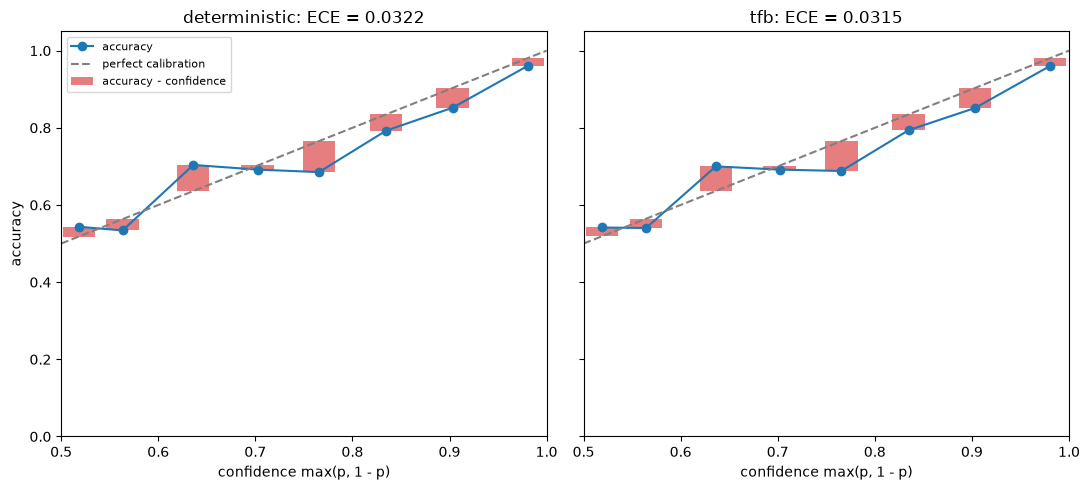

In [9]:
# ---------------------------------------------------------------------------
# Predictive quality on the test set: deterministic vs TFB.
# ---------------------------------------------------------------------------


def predictive_metrics(logits: Tensor, targets: Tensor) -> dict[str, float]:
    """
    Accuracy, BMA NLL, and ECE of a binary BMA predictive.

    :param logits:  Per-sample logits, ``[N, D, 1]``.
    :param targets: Binary targets, ``[D, 1]``.
    :return:        Metric name to value.
    """
    p_bar = decompose(logits).p_bar[:, 0]
    y = targets[:, 0]
    return {
        "accuracy": ((p_bar >= UNSAFE_THRESHOLD).float() == y).float().mean().item(),
        "nll": bma_nll(logits, targets),
        "ece": expected_calibration_error(p_bar, y),
    }


test_logits = {
    "deterministic": collect_logits(safety_model, posterior, test_loader, 0.0, 1),
    "tfb": collect_logits(safety_model, posterior, test_loader, sigma_star, N_EVAL_SAMPLES),
}
quality = {name: predictive_metrics(logits, y_test) for name, logits in test_logits.items()}

print(f"{'model':<15}{'accuracy':>10}{'NLL':>10}{'ECE':>10}")
for name, metrics in quality.items():
    print(f"{name:<15}{metrics['accuracy']:>10.4f}{metrics['nll']:>10.4f}{metrics['ece']:>10.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, (name, logits) in zip(axes, test_logits.items(), strict=True):
    conf, acc, counts = reliability_bins(decompose(logits).p_bar[:, 0], y_test[:, 0], ECE_BINS)
    filled = counts > 0
    ax.bar(conf[filled], acc[filled] - conf[filled], bottom=conf[filled], width=0.5 / ECE_BINS,
           color="tab:red", alpha=0.6, label="accuracy - confidence")
    ax.plot(conf[filled], acc[filled], marker="o", color="tab:blue", label="accuracy")
    ax.plot([0.5, 1.0], [0.5, 1.0], linestyle="--", color="gray", label="perfect calibration")
    ax.set_xlim(0.5, 1.0)
    ax.set_ylim(0.0, 1.05)
    ax.set_xlabel("confidence max(p, 1 - p)")
    ax.set_title(f"{name}: ECE = {quality[name]['ece']:.4f}")
axes[0].set_ylabel("accuracy")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Test errors: 258 / 1710 (AUPRC baseline = error rate 0.151)
score                        AUROC   AUPRC
TU (TFB)                    0.7980  0.3665
AU (TFB)                    0.7979  0.3723
EU (TFB)                    0.7893  0.3357
Var[f] (TFB)                0.5651  0.1743
entropy (deterministic)     0.7979  0.3666


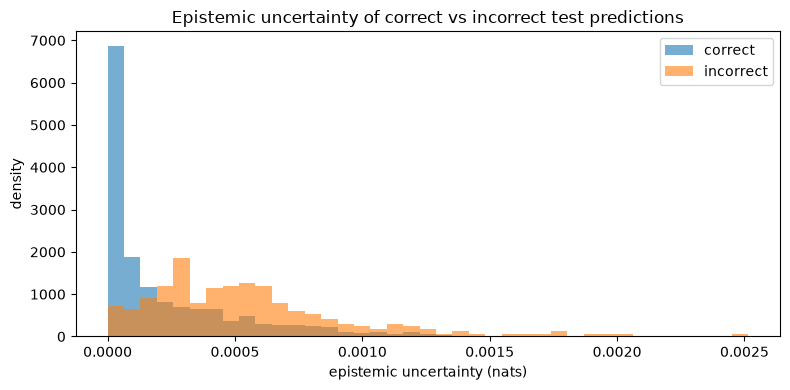

In [10]:
# ---------------------------------------------------------------------------
# Misclassification detection: do the uncertainty scores flag wrong predictions?
# ---------------------------------------------------------------------------

test_decomposition = decompose(test_logits["tfb"])
test_errors = (
    ((test_decomposition.p_bar[:, 0] >= UNSAFE_THRESHOLD).float() != y_test[:, 0]).numpy()
)
error_scores = {
    "TU (TFB)": test_decomposition.total[:, 0].numpy(),
    "AU (TFB)": test_decomposition.aleatoric[:, 0].numpy(),
    "EU (TFB)": test_decomposition.epistemic[:, 0].numpy(),
    "Var[f] (TFB)": test_decomposition.logit_variance[:, 0].numpy(),
    "entropy (deterministic)": decompose(test_logits["deterministic"]).total[:, 0].numpy(),
}
misclassification = {
    name: {"auroc": auroc(scores, test_errors), "auprc": auprc(scores, test_errors)}
    for name, scores in error_scores.items()
}

print(f"Test errors: {int(test_errors.sum())} / {len(test_errors)} (AUPRC baseline = error rate {test_errors.mean():.3f})")
print(f"{'score':<26}{'AUROC':>8}{'AUPRC':>8}")
for name, values in misclassification.items():
    print(f"{name:<26}{values['auroc']:>8.4f}{values['auprc']:>8.4f}")

eu = error_scores["EU (TFB)"]
bins = np.linspace(0.0, max(eu.max(), 1e-8), 40)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(eu[~test_errors], bins=bins, alpha=0.6, density=True, label="correct")
ax.hist(eu[test_errors], bins=bins, alpha=0.6, density=True, label="incorrect")
ax.set_xlabel("epistemic uncertainty (nats)")
ax.set_ylabel("density")
ax.set_title("Epistemic uncertainty of correct vs incorrect test predictions")
ax.legend()
plt.tight_layout()
plt.show()

Filter:   0%|          | 0/2073 [00:00<?, ? examples/s]

Filter:   0%|          | 0/500 [00:00<?, ? examples/s]

set             size   mean EU  AUROC EU  mean Var[f]  AUROC Var[f]
Aegis test      1710   0.00028         -    6.228e-03             -
wikitext-2       878   0.00015    0.4475    2.678e-03        0.1764
no_robots        411   0.00026    0.5475    4.330e-03        0.3403


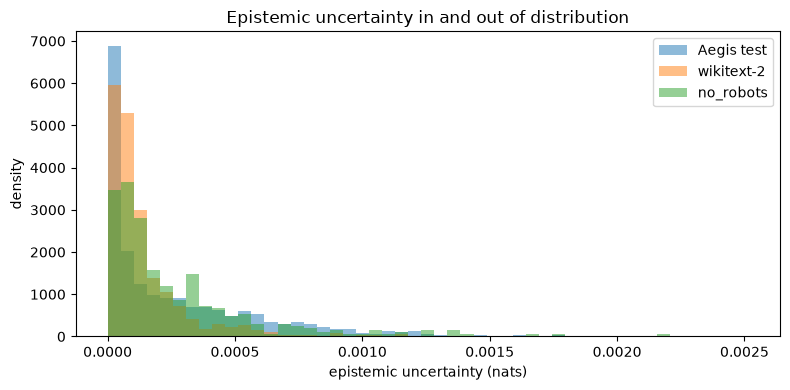

In [11]:
# ---------------------------------------------------------------------------
# Distribution shift: epistemic uncertainty on non-safety text.
# ---------------------------------------------------------------------------


def text_dataset(texts: list[str], size: int) -> HFDataset:
    """
    Wrap raw texts as records the Aegis collate function accepts.

    :param texts:   Raw texts.
    :param size:    Number of texts to keep after the token-length filter.
    :return:        Records with a ``prompt`` column and a placeholder ``prompt_label``
                    (these corpora carry no safety label; it is never evaluated).
    """
    records = HFDataset.from_dict(
        {AegisKeys.PROMPT.value: texts, AegisKeys.PROMPT_LABEL.value: [AegisLabels.SAFE.value] * len(texts)}
    )
    return filter_by_token_length(records, tokenizer, MAX_LEN, size)


wikitext = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="test")
wikitext_texts = [
    line.strip()
    for line in wikitext["text"]
    if len(line.strip()) >= OOD_MIN_CHARS and not line.strip().startswith("=")
]
no_robots = load_dataset("HuggingFaceH4/no_robots", split="test")

ood_datasets = {
    "wikitext-2": text_dataset(wikitext_texts, OOD_SIZE),
    "no_robots": text_dataset(list(no_robots["prompt"]), OOD_SIZE),
}
ood_decompositions = {
    name: decompose(collect_logits(safety_model, posterior, make_loader(ds), sigma_star, N_EVAL_SAMPLES))
    for name, ds in ood_datasets.items()
}

# AUROC treats the out-of-distribution texts as positives against the Aegis test split.
eu_in = test_decomposition.epistemic[:, 0].numpy()
var_in = test_decomposition.logit_variance[:, 0].numpy()
ood_auroc: dict[str, float] = {}
ood_auroc_logit_variance: dict[str, float] = {}
print(f"{'set':<14}{'size':>6}{'mean EU':>10}{'AUROC EU':>10}{'mean Var[f]':>13}{'AUROC Var[f]':>14}")
print(f"{'Aegis test':<14}{len(eu_in):>6}{eu_in.mean():>10.5f}{'-':>10}{var_in.mean():>13.3e}{'-':>14}")
for name, decomposition in ood_decompositions.items():
    eu_out = decomposition.epistemic[:, 0].numpy()
    var_out = decomposition.logit_variance[:, 0].numpy()
    is_ood = np.concatenate([np.zeros(len(eu_in), bool), np.ones(len(eu_out), bool)])
    ood_auroc[name] = auroc(np.concatenate([eu_in, eu_out]), is_ood)
    ood_auroc_logit_variance[name] = auroc(np.concatenate([var_in, var_out]), is_ood)
    print(
        f"{name:<14}{len(eu_out):>6}{eu_out.mean():>10.5f}{ood_auroc[name]:>10.4f}"
        f"{var_out.mean():>13.3e}{ood_auroc_logit_variance[name]:>14.4f}"
    )

all_eu = np.concatenate([eu_in] + [d.epistemic[:, 0].numpy() for d in ood_decompositions.values()])
bins = np.linspace(0.0, max(all_eu.max(), 1e-8), 50)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(eu_in, bins=bins, alpha=0.5, density=True, label="Aegis test")
for name, decomposition in ood_decompositions.items():
    ax.hist(decomposition.epistemic[:, 0].numpy(), bins=bins, alpha=0.5, density=True, label=name)
ax.set_xlabel("epistemic uncertainty (nats)")
ax.set_ylabel("density")
ax.set_title("Epistemic uncertainty in and out of distribution")
ax.legend()
plt.tight_layout()
plt.show()

{
  "num_disagreement": 211,
  "mean_au_disagreement": 0.4445694386959076,
  "mean_au_rest": 0.26813408732414246,
  "mean_eu_disagreement": 0.0004731549124699086,
  "mean_eu_rest": 0.0002517190878279507,
  "auroc_au": 0.7164286375045776,
  "auroc_eu": 0.710699737071991
}


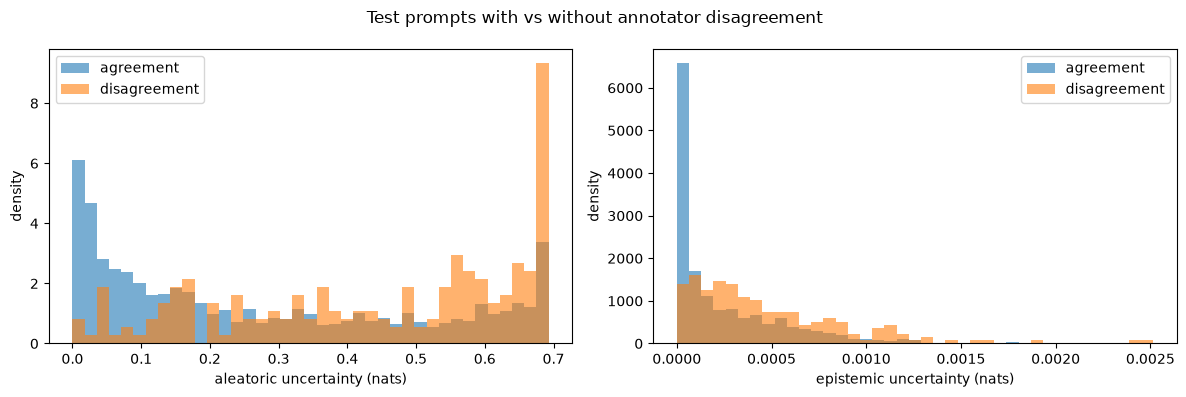

In [12]:
# ---------------------------------------------------------------------------
# Aleatoric sanity check: prompts with annotator disagreement.
# ---------------------------------------------------------------------------


def has_annotator_disagreement(row: dict[str, Any]) -> bool:
    """
    Flag prompts whose aggregated annotations disagree.

    A record disagrees when it carries ``Needs Caution`` (a non-unsafe vote), or
    when it is labeled safe yet lists an unsafe category (a minority unsafe vote).

    :param row: An Aegis record.
    :return:    True for disagreement prompts.
    """
    raw = row[AegisKeys.VIOLATED_CATEGORIES] or ""
    categories = [category.strip() for category in raw.split(",") if category.strip()]
    if NEEDS_CAUTION in categories:
        return True
    is_safe = row[AegisKeys.PROMPT_LABEL] == AegisLabels.SAFE
    return is_safe and any(category != NEEDS_CAUTION for category in categories)


disagreement = np.array([has_annotator_disagreement(row) for row in test_dataset])
au_test = test_decomposition.aleatoric[:, 0].numpy()
aleatoric_check = {
    "num_disagreement": int(disagreement.sum()),
    "mean_au_disagreement": float(au_test[disagreement].mean()),
    "mean_au_rest": float(au_test[~disagreement].mean()),
    "mean_eu_disagreement": float(eu_in[disagreement].mean()),
    "mean_eu_rest": float(eu_in[~disagreement].mean()),
    "auroc_au": auroc(au_test, disagreement),
    "auroc_eu": auroc(eu_in, disagreement),
}
print(json.dumps(aleatoric_check, indent=2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (label, values) in zip(axes, [("aleatoric", au_test), ("epistemic", eu_in)], strict=True):
    bins = np.linspace(0.0, max(values.max(), 1e-8), 40)
    ax.hist(values[~disagreement], bins=bins, alpha=0.6, density=True, label="agreement")
    ax.hist(values[disagreement], bins=bins, alpha=0.6, density=True, label="disagreement")
    ax.set_xlabel(f"{label} uncertainty (nats)")
    ax.set_ylabel("density")
    ax.legend()
fig.suptitle("Test prompts with vs without annotator disagreement")
plt.tight_layout()
plt.show()

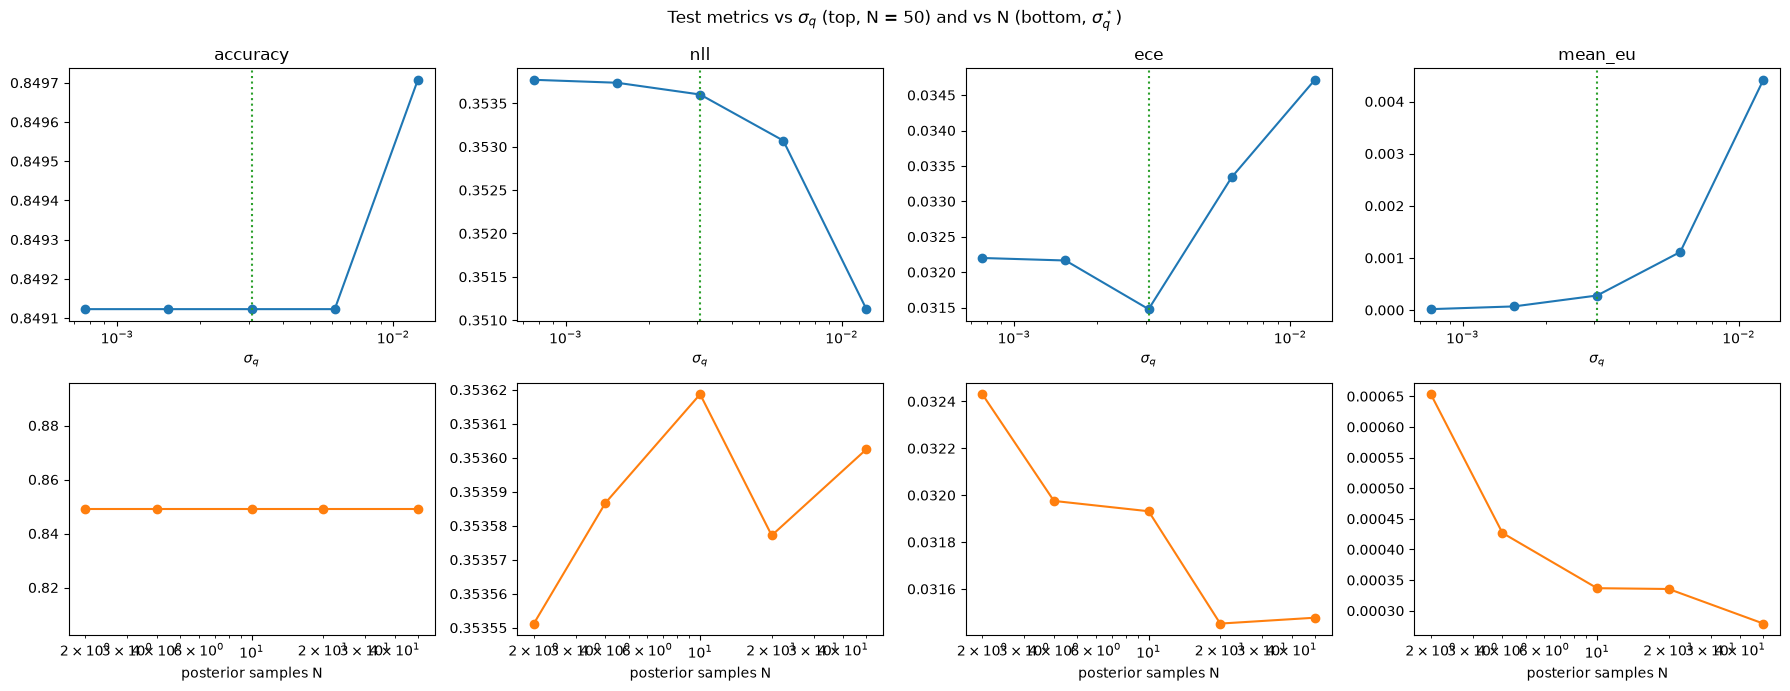

In [13]:
# ---------------------------------------------------------------------------
# Sensitivity to the noise scale and to the number of posterior samples.
# ---------------------------------------------------------------------------


def summary_metrics(logits: Tensor, targets: Tensor) -> dict[str, float]:
    """
    Predictive metrics plus the mean epistemic uncertainty.

    :param logits:  Per-sample logits, ``[N, D, 1]``.
    :param targets: Binary targets, ``[D, 1]``.
    :return:        Metric name to value.
    """
    return {**predictive_metrics(logits, targets), "mean_eu": decompose(logits).epistemic.mean().item()}


sigma_grid = [factor * sigma_star for factor in SIGMA_GRID_FACTORS]
sigma_sweep = [
    summary_metrics(collect_logits(safety_model, posterior, test_loader, sigma, N_EVAL_SAMPLES), y_test)
    for sigma in sigma_grid
]

# Samples are seeded individually, so the first N of a larger run equal an N-sample run.
logits_max_n = collect_logits(safety_model, posterior, test_loader, sigma_star, max(N_SWEEP))
n_sweep = [summary_metrics(logits_max_n[:n], y_test) for n in N_SWEEP]

metric_names = ["accuracy", "nll", "ece", "mean_eu"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for column, metric in enumerate(metric_names):
    axes[0, column].plot(sigma_grid, [m[metric] for m in sigma_sweep], marker="o")
    axes[0, column].axvline(sigma_star, color="tab:green", linestyle=":")
    axes[0, column].set_xscale("log")
    axes[0, column].set_xlabel(r"$\sigma_q$")
    axes[0, column].set_title(metric)
    axes[1, column].plot(N_SWEEP, [m[metric] for m in n_sweep], marker="o", color="tab:orange")
    axes[1, column].set_xscale("log")
    axes[1, column].set_xlabel("posterior samples N")
fig.suptitle(r"Test metrics vs $\sigma_q$ (top, N = %d) and vs N (bottom, $\sigma_q^\star$)" % N_EVAL_SAMPLES)
plt.tight_layout()
plt.show()

## Train vs test epistemic uncertainty

Reported for completeness only. Both splits are in-distribution and $\epsilon$ deliberately keeps the posterior tight around the trained weights, so a small or absent gap is expected and does not indicate a problem (ADR Decision 5). The informative tests are the misclassification, distribution-shift, and aleatoric analyses above.

mean EU: train 0.00027 | test 0.00028


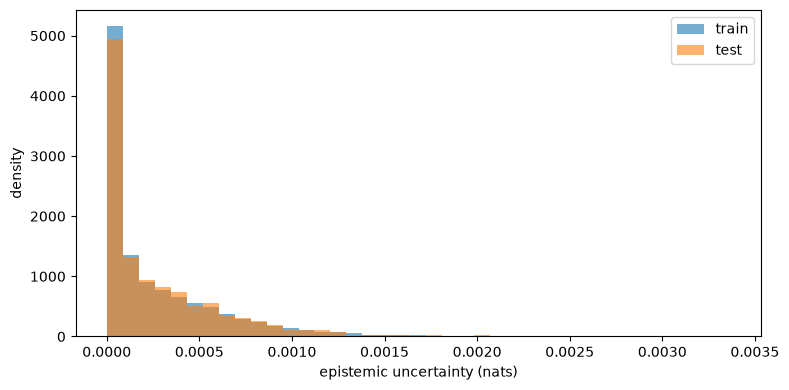

In [14]:
train_decomposition = decompose(collect_logits(safety_model, posterior, train_loader, sigma_star, N_EVAL_SAMPLES))
eu_train = train_decomposition.epistemic[:, 0].numpy()
print(f"mean EU: train {eu_train.mean():.5f} | test {eu_in.mean():.5f}")

bins = np.linspace(0.0, max(eu_train.max(), eu_in.max(), 1e-8), 40)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(eu_train, bins=bins, alpha=0.6, density=True, label="train")
ax.hist(eu_in, bins=bins, alpha=0.6, density=True, label="test")
ax.set_xlabel("epistemic uncertainty (nats)")
ax.set_ylabel("density")
ax.legend()
plt.tight_layout()
plt.show()

## Phase 2: Bayesianizing the feed-forward head

The LoRA posterior perturbs only the encoder. The optional phase-2 variant of ADR Decision 2 also perturbs every weight matrix of the head,

$$\mathbf{W}^{\text{head}}_k + \sigma_h\,\rho_k\,\mathbf{\Xi}_k, \qquad k = 1, \dots, 5,$$

where $\mathbf{\Xi}_k$ has independent standard-normal entries, $\rho_k$ is the root-mean-square of the entries of $\mathbf{W}^{\text{head}}_k$, and the biases stay deterministic. The five matrices have shapes $512\times 384$, three times $512\times 512$, and $1\times 512$. The factor $\rho_k$ makes $\sigma_h$ a *relative* noise level, because the head's layers have different weight scales.

$\sigma_h$ is searched after $\sigma_q$ is fixed. It is the largest value with $|\mathcal{L}(\sigma_q^\star, \sigma_h) - \mathcal{L}(\sigma_q^\star, 0)| \le \epsilon$, using the same anchor set, pseudo-labels and $\epsilon$ as the LoRA search. Head sample $n$ carries the sign of LoRA sample $n$, so the pair $(\mathbf{Z}, \mathbf{\Xi})$ is jointly antithetic. The head runs on cached mean-pooled encoder outputs $\mathbf{h}(x) \in \mathbb{R}^{384}$, so head samples are almost free once the encoder outputs exist.

Three posteriors are compared under the protocol of Decision 5: LoRA only (phase 1), head only ($\sigma_q = 0$, $\sigma_h^\star$), and LoRA + head ($\sigma_q^\star$, $\sigma_h^\star$).

In [15]:
# ---------------------------------------------------------------------------
# Phase 2: head posterior and cached encoder outputs (ADR Decision 2).
# ---------------------------------------------------------------------------


def predict_embeddings(model: SafetyModel, loader: DataLoader) -> Tensor:
    """
    Mean-pooled encoder outputs under the model's current adapter weights.

    :param model:   The safety model (in evaluation mode).
    :param loader:  Loader yielding ``(batch_dict, targets)``.
    :return:        Pooled embeddings of shape ``[D, H]`` on the CPU.
    """
    outputs: list[Tensor] = []
    with torch.no_grad():
        for batch_dict, _ in loader:
            batch_dict = {k: v.to(device) for k, v in batch_dict.items()}
            # [B, L, H] -> [B, H], exactly as in SafetyModel.forward.
            hidden = model._embedding_model(**batch_dict).last_hidden_state
            outputs.append(average_pool(hidden, batch_dict["attention_mask"]).float().cpu())
    return torch.cat(outputs)


def collect_embeddings(
    model: SafetyModel,
    posterior: TFBPosterior,
    loader: DataLoader,
    sigma: float,
    n_samples: int,
) -> Tensor:
    """
    Per-sample encoder outputs under the LoRA posterior.

    :param model:       The safety model (in evaluation mode).
    :param posterior:   The TFB posterior sampler.
    :param loader:      Loader yielding ``(batch_dict, targets)``.
    :param sigma:       LoRA noise scale ``sigma_q``; ``0`` returns a single sample.
    :param n_samples:   Number of posterior samples ``N`` (even).
    :return:            Pooled embeddings of shape ``[N, D, H]`` on the CPU.
    """
    if sigma == 0.0:
        return predict_embeddings(model, loader).unsqueeze(0)
    if n_samples % 2:
        raise ValueError(f"n_samples must be even for antithetic pairs, got {n_samples}")

    samples: list[Tensor] = []
    for n in range(n_samples):
        with posterior.sample(n, sigma):
            samples.append(predict_embeddings(model, loader))
    return torch.stack(samples)


class HeadPosterior:
    """
    Sampler for the full-rank isotropic Gaussian over the head's weight matrices.

    Sample ``n`` replaces every weight matrix ``W_k`` by ``W_k + sigma_h * rho_k * Xi_{k,n}``,
    with ``rho_k`` the root-mean-square entry of ``W_k``. As in :class:`TFBPosterior`,
    samples ``2k`` and ``2k + 1`` use ``+Xi_k`` and ``-Xi_k`` drawn from the seed
    ``seed + k``. The trained head is never modified; samples are applied with
    :func:`torch.func.functional_call`.

    :param head:    The trained feed-forward head.
    :param seed:    Base seed of the per-pair generators.
    """

    def __init__(self, head: nn.Module, seed: int) -> None:
        self.seed = seed
        self.means: dict[str, Tensor] = {
            f"{name}.weight": module.weight.detach().clone()
            for name, module in head.named_modules()
            if isinstance(module, nn.Linear)
        }
        self.rms: dict[str, float] = {
            name: weight.pow(2).mean().sqrt().item() for name, weight in self.means.items()
        }
        self._standard_normals: list[dict[str, Tensor]] = []

    def standard_normals(self, n: int) -> dict[str, Tensor]:
        """
        Standard-normal matrices of sample ``n``, keyed like :attr:`means`.

        :param n:   Sample index; ``n // 2`` selects the pair and ``n % 2`` the sign.
        :return:    One matrix per weight, on the weight's device.
        """
        pair, negate = divmod(n, 2)
        while len(self._standard_normals) <= pair:
            generator = torch.Generator().manual_seed(self.seed + len(self._standard_normals))
            self._standard_normals.append(
                {
                    name: torch.randn(mean.shape, generator=generator).to(mean)
                    for name, mean in self.means.items()
                }
            )
        normals = self._standard_normals[pair]
        return {name: -z for name, z in normals.items()} if negate else normals

    def weights(self, n: int, sigma: float) -> dict[str, Tensor]:
        """
        Weight matrices of head sample ``n`` at relative noise level ``sigma``.

        :param n:       Sample index.
        :param sigma:   Relative head noise scale ``sigma_h``.
        :return:        Parameter name to sampled weight, for ``functional_call``.
        """
        if sigma == 0.0:
            return self.means
        normals = self.standard_normals(n)
        return {
            name: mean + sigma * self.rms[name] * normals[name] for name, mean in self.means.items()
        }


def head_logits(
    head: nn.Module,
    posterior: HeadPosterior,
    embeddings: Tensor,
    sigma: float,
    n_samples: int,
) -> Tensor:
    """
    Per-sample head logits on cached encoder outputs.

    A single encoder sample (deterministic encoder) is shared by every head sample.
    Otherwise head sample ``n`` reads encoder sample ``n``, pairing the LoRA and
    head noise of the same index. With ``sigma == 0`` the head is deterministic and
    one logit sample is returned per encoder sample.

    :param head:        The trained feed-forward head.
    :param posterior:   The head posterior sampler.
    :param embeddings:  Encoder outputs, ``[N_e, D, H]`` with ``N_e`` 1 or ``n_samples``.
    :param sigma:       Relative head noise scale ``sigma_h``.
    :param n_samples:   Number of head samples (even when ``sigma > 0``).
    :return:            Logits of shape ``[N, D, K]`` on the CPU.
    """
    num_encoder = embeddings.shape[0]
    if sigma == 0.0:
        n_samples = num_encoder
    elif n_samples % 2:
        raise ValueError(f"n_samples must be even for antithetic pairs, got {n_samples}")
    if num_encoder not in (1, n_samples):
        raise ValueError(f"{num_encoder} encoder samples cannot pair with {n_samples} head samples")

    samples: list[Tensor] = []
    with torch.no_grad():
        for n in range(n_samples):
            # [D, H] -> [D] (BinaryFFN squeezes its single output) -> [D, K]
            x = embeddings[n if num_encoder > 1 else 0].to(device)
            logits = functional_call(head, posterior.weights(n, sigma), (x,))
            samples.append(logits.reshape(x.shape[0], -1).float().cpu())
    return torch.stack(samples)


head_posterior = HeadPosterior(ffn, SEED + HEAD_SEED_OFFSET)
for name, mean in head_posterior.means.items():
    print(f"{name:<20}{str(tuple(mean.shape)):>12}  rms = {head_posterior.rms[name]:.4f}")

# The cached-embedding route with a noise-free head must reproduce the full model,
# and paired head samples must carry exactly opposite noise.
check_embeddings = collect_embeddings(safety_model, posterior, check_loader, 0.0, 1)
cached_route_error = (head_logits(ffn, head_posterior, check_embeddings, 0.0, 1)[0] - logits_before).abs().max().item()
print(f"max logit change through cached embeddings = {cached_route_error:.2e}")
assert cached_route_error < 1e-4
assert all(
    torch.equal(head_posterior.standard_normals(0)[name], -head_posterior.standard_normals(1)[name])
    for name in head_posterior.means
)

model.00_Linear.weight  (512, 384)  rms = 0.0303
model.01_Linear.weight  (512, 512)  rms = 0.0368
model.02_Linear.weight  (512, 512)  rms = 0.0358
model.03_Linear.weight  (512, 512)  rms = 0.0352
model.04_Linear.weight    (1, 512)  rms = 0.0714
max logit change through cached embeddings = 1.24e-05


L(0) = 0.1415, L(sigma_q*, 0) = 0.1419, epsilon = 4.25e-04
sigma_h_star = 6.313e-02 (relative to each layer's weight rms)


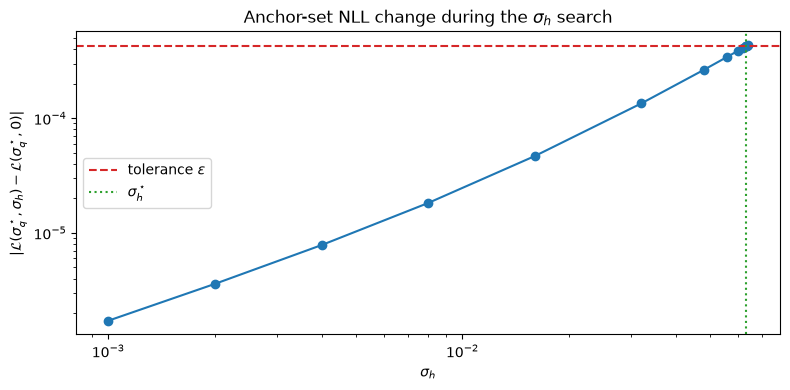

In [16]:
# ---------------------------------------------------------------------------
# Search sigma_h with the LoRA posterior fixed at sigma_q* (ADR Decision 2).
# ---------------------------------------------------------------------------

# Anchor encoder outputs under the LoRA posterior are computed once and reused by
# every candidate sigma_h, which only reruns the head.
anchor_embeddings = collect_embeddings(safety_model, posterior, anchor_loader, sigma_star, N_SEARCH_SAMPLES)


def anchor_nll_head(sigma_h: float) -> float:
    logits = head_logits(ffn, head_posterior, anchor_embeddings, sigma_h, N_SEARCH_SAMPLES)
    return gibbs_nll(logits, pseudo_labels)


nll_lora = anchor_nll_head(0.0)
sigma_h_star, head_trace = search_sigma(anchor_nll_head, epsilon)
print(f"L(0) = {nll_zero:.4f}, L(sigma_q*, 0) = {nll_lora:.4f}, epsilon = {epsilon:.2e}")
print(f"sigma_h_star = {sigma_h_star:.3e} (relative to each layer's weight rms)")

head_sigmas = np.array([s for s, _ in head_trace[1:]])
head_changes = np.array([abs(v - nll_lora) for _, v in head_trace[1:]])
order = np.argsort(head_sigmas)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(head_sigmas[order], np.maximum(head_changes[order], 1e-12), marker="o")
ax.axhline(epsilon, color="tab:red", linestyle="--", label=r"tolerance $\epsilon$")
ax.axvline(sigma_h_star, color="tab:green", linestyle=":", label=r"$\sigma_h^\star$")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$\sigma_h$")
ax.set_ylabel(r"$|\mathcal{L}(\sigma_q^\star, \sigma_h) - \mathcal{L}(\sigma_q^\star, 0)|$")
ax.set_title(r"Anchor-set NLL change during the $\sigma_h$ search")
ax.legend()
plt.tight_layout()
plt.show()

max |phase-2 LoRA logits - phase-1 TFB logits| = 6.68e-06

posterior         accuracy       NLL       ECE    mean EU  mean Var[f]
deterministic       0.8491    0.3538    0.0322    0.00000    0.000e+00
LoRA (phase 1)      0.8491    0.3536    0.0315    0.00028    6.228e-03
head only           0.8491    0.3537    0.0322    0.00024    5.989e-03
LoRA + head         0.8491    0.3535    0.0309    0.00060    1.407e-02

Misclassification detection on the test set
posterior       score    error rate   AUROC   AUPRC
LoRA (phase 1)  EU            0.151  0.7893  0.3357
LoRA (phase 1)  Var[f]        0.151  0.5651  0.1743
head only       EU            0.151  0.7948  0.3449
head only       Var[f]        0.151  0.3836  0.1143
LoRA + head     EU            0.151  0.7933  0.3362
LoRA + head     Var[f]        0.151  0.5160  0.1554

Out-of-distribution AUROC vs Aegis test
posterior       score       wikitext-2     no_robots
LoRA (phase 1)  EU              0.4475        0.5475
LoRA (phase 1)  Var[f]        

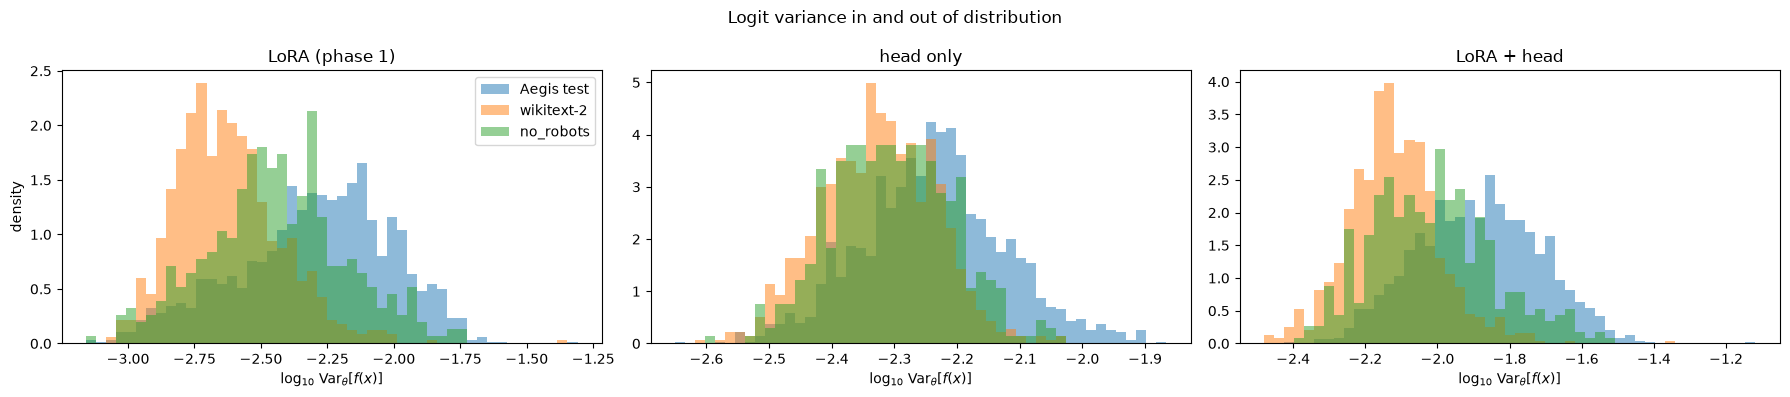

In [17]:
# ---------------------------------------------------------------------------
# Compare the LoRA-only, head-only, and LoRA + head posteriors (ADR Decision 5).
# ---------------------------------------------------------------------------

PHASE2_LABELS = {
    "deterministic": "deterministic",
    "lora": "LoRA (phase 1)",
    "head": "head only",
    "lora_head": "LoRA + head",
}
PHASE2_VARIANTS = ["lora", "head", "lora_head"]

# Encoder outputs for the test and out-of-distribution sets, deterministic and under
# the LoRA posterior; every head variant is then a cheap pass over these caches.
eval_sets = {"test": test_dataset, **ood_datasets}
phase2_logits: dict[str, dict[str, Tensor]] = {}
for set_name, dataset in eval_sets.items():
    loader = make_loader(dataset)
    deterministic_outputs = collect_embeddings(safety_model, posterior, loader, 0.0, 1)
    lora_outputs = collect_embeddings(safety_model, posterior, loader, sigma_star, N_EVAL_SAMPLES)
    phase2_logits[set_name] = {
        "deterministic": head_logits(ffn, head_posterior, deterministic_outputs, 0.0, 1),
        "lora": head_logits(ffn, head_posterior, lora_outputs, 0.0, N_EVAL_SAMPLES),
        "head": head_logits(ffn, head_posterior, deterministic_outputs, sigma_h_star, N_EVAL_SAMPLES),
        "lora_head": head_logits(ffn, head_posterior, lora_outputs, sigma_h_star, N_EVAL_SAMPLES),
    }

# The cached route reuses the LoRA noise of phase 1, so it must reproduce its logits.
phase1_error = (phase2_logits["test"]["lora"] - test_logits["tfb"]).abs().max().item()
print(f"max |phase-2 LoRA logits - phase-1 TFB logits| = {phase1_error:.2e}")
assert phase1_error < 1e-4

phase2_decompositions = {
    set_name: {variant: decompose(logits) for variant, logits in by_variant.items()}
    for set_name, by_variant in phase2_logits.items()
}
test_by_variant = phase2_decompositions["test"]

# Predictive quality and uncertainty magnitudes on the test set.
phase2_quality = {
    variant: {
        **predictive_metrics(phase2_logits["test"][variant], y_test),
        "mean_eu": test_by_variant[variant].epistemic.mean().item(),
        "mean_logit_variance": test_by_variant[variant].logit_variance.mean().item(),
    }
    for variant in ["deterministic", *PHASE2_VARIANTS]
}
print(f"\n{'posterior':<16}{'accuracy':>10}{'NLL':>10}{'ECE':>10}{'mean EU':>11}{'mean Var[f]':>13}")
for variant, metrics in phase2_quality.items():
    print(
        f"{PHASE2_LABELS[variant]:<16}{metrics['accuracy']:>10.4f}{metrics['nll']:>10.4f}"
        f"{metrics['ece']:>10.4f}{metrics['mean_eu']:>11.5f}{metrics['mean_logit_variance']:>13.3e}"
    )


def uncertainty_scores(decomposition: Decomposition) -> dict[str, np.ndarray]:
    return {
        "EU": decomposition.epistemic[:, 0].numpy(),
        "Var[f]": decomposition.logit_variance[:, 0].numpy(),
    }


# Misclassification detection, with errors defined by each variant's own BMA prediction.
phase2_misclassification: dict[str, dict[str, dict[str, float]]] = {}
for variant in PHASE2_VARIANTS:
    decomposition = test_by_variant[variant]
    errors = ((decomposition.p_bar[:, 0] >= UNSAFE_THRESHOLD).float() != y_test[:, 0]).numpy()
    phase2_misclassification[variant] = {
        score: {"auroc": auroc(values, errors), "auprc": auprc(values, errors), "error_rate": float(errors.mean())}
        for score, values in uncertainty_scores(decomposition).items()
    }

# Distribution shift: each out-of-distribution set against the Aegis test split.
phase2_ood_auroc: dict[str, dict[str, dict[str, float]]] = {}
for variant in PHASE2_VARIANTS:
    scores_in = uncertainty_scores(test_by_variant[variant])
    phase2_ood_auroc[variant] = {}
    for set_name in ood_datasets:
        scores_out = uncertainty_scores(phase2_decompositions[set_name][variant])
        is_ood = np.concatenate([np.zeros(len(scores_in["EU"]), bool), np.ones(len(scores_out["EU"]), bool)])
        phase2_ood_auroc[variant][set_name] = {
            score: auroc(np.concatenate([scores_in[score], scores_out[score]]), is_ood) for score in scores_in
        }

# Aleatoric sanity check: AU should still track annotator disagreement.
phase2_aleatoric_auroc = {
    variant: auroc(test_by_variant[variant].aleatoric[:, 0].numpy(), disagreement)
    for variant in PHASE2_VARIANTS
}

print("\nMisclassification detection on the test set")
print(f"{'posterior':<16}{'score':<8}{'error rate':>11}{'AUROC':>8}{'AUPRC':>8}")
for variant in PHASE2_VARIANTS:
    for score, metrics in phase2_misclassification[variant].items():
        print(
            f"{PHASE2_LABELS[variant]:<16}{score:<8}{metrics['error_rate']:>11.3f}"
            f"{metrics['auroc']:>8.4f}{metrics['auprc']:>8.4f}"
        )

ood_names = list(ood_datasets)
print("\nOut-of-distribution AUROC vs Aegis test")
print(f"{'posterior':<16}{'score':<8}" + "".join(f"{name:>14}" for name in ood_names))
for variant in PHASE2_VARIANTS:
    for score in ("EU", "Var[f]"):
        columns = "".join(f"{phase2_ood_auroc[variant][name][score]:>14.4f}" for name in ood_names)
        print(f"{PHASE2_LABELS[variant]:<16}{score:<8}{columns}")
print("\nAU vs annotator disagreement AUROC: " + ", ".join(
    f"{PHASE2_LABELS[v]} {phase2_aleatoric_auroc[v]:.4f}" for v in PHASE2_VARIANTS
))

# Logit variance in and out of distribution, one panel per posterior, on a log scale
# because the three posteriors differ by orders of magnitude.
fig, axes = plt.subplots(1, len(PHASE2_VARIANTS), figsize=(6 * len(PHASE2_VARIANTS), 4))
for ax, variant in zip(axes, PHASE2_VARIANTS, strict=True):
    log_variances = {
        set_name: np.log10(by_variant[variant].logit_variance[:, 0].numpy() + 1e-12)
        for set_name, by_variant in phase2_decompositions.items()
    }
    pooled = np.concatenate(list(log_variances.values()))
    bins = np.linspace(pooled.min(), max(pooled.max(), pooled.min() + 1e-6), 50)
    for set_name, values in log_variances.items():
        ax.hist(values, bins=bins, alpha=0.5, density=True, label="Aegis test" if set_name == "test" else set_name)
    ax.set_xlabel(r"$\log_{10}\,\mathrm{Var}_\theta[f(x)]$")
    ax.set_title(PHASE2_LABELS[variant])
axes[0].set_ylabel("density")
axes[0].legend()
fig.suptitle("Logit variance in and out of distribution")
plt.tight_layout()
plt.show()

In [18]:
# ---------------------------------------------------------------------------
# Persist the results and restore the trained adapters.
# ---------------------------------------------------------------------------

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
summary = {
    "checkpoint_epoch": config["epoch"],
    "n_search_samples": N_SEARCH_SAMPLES,
    "n_eval_samples": N_EVAL_SAMPLES,
    "anchor_size": len(anchor_indices),
    "nll_zero": nll_zero,
    "epsilon": epsilon,
    "sigma_star": sigma_star,
    "sigma_star_accuracy": sigma_star_accuracy,
    "search_trace": nll_trace,
    "effective_ranks": r_eff,
    "test_quality": quality,
    "misclassification": misclassification,
    "ood_auroc": ood_auroc,
    "ood_auroc_logit_variance": ood_auroc_logit_variance,
    "aleatoric_check": aleatoric_check,
    "sigma_sweep": dict(zip(map(str, sigma_grid), sigma_sweep, strict=True)),
    "n_sweep": dict(zip(map(str, N_SWEEP), n_sweep, strict=True)),
    "head": {
        "sigma_h_star": sigma_h_star,
        "nll_lora": nll_lora,
        "search_trace": head_trace,
        "weight_rms": head_posterior.rms,
        "quality": phase2_quality,
        "misclassification": phase2_misclassification,
        "ood_auroc": phase2_ood_auroc,
        "aleatoric_auroc": phase2_aleatoric_auroc,
    },
}
(RESULTS_DIR / "summary.json").write_text(json.dumps(summary, indent=2))

score_sets = {"train": train_decomposition, "test": test_decomposition, **ood_decompositions}
np.savez(
    RESULTS_DIR / "scores.npz",
    **{
        f"{name}_{field}": getattr(decomposition, field)[:, 0].numpy()
        for name, decomposition in score_sets.items()
        for field in ("p_bar", "total", "aleatoric", "epistemic", "logit_variance")
    },
    **{
        f"phase2_{variant}_{set_name}_{field}": getattr(decomposition, field)[:, 0].numpy()
        for set_name, by_variant in phase2_decompositions.items()
        for variant, decomposition in by_variant.items()
        for field in ("p_bar", "epistemic", "logit_variance")
    },
)
print(f"Wrote {RESULTS_DIR / 'summary.json'} and {RESULTS_DIR / 'scores.npz'}")

restore_original_lora(tfb_layers)
restored_error = (predict_logits(safety_model, check_loader) - logits_before).abs().max().item()
print(f"Restored trained adapters (max logit change {restored_error:.2e})")

Wrote ../outputs/binary_classifier/me5s_lora_binary/uncertainty/summary.json and ../outputs/binary_classifier/me5s_lora_binary/uncertainty/scores.npz
Restored trained adapters (max logit change 0.00e+00)


All three notebooks ran cleanly on the cleaned data. The binary classifier improved a lot: test accuracy is 0.849, up from 0.809 in the earlier uncleaned run. The multi-label model learns the coarse labels well but over-predicts rare categories at the default 0.5 threshold. TFB leaves accuracy and calibration unchanged and flags likely errors about as well as plain softmax entropy, but it does not detect out-of-distribution text.

## Key takeaways from all three notebooks

### Binary classifier
* The best checkpoint is epoch 10, with validation loss 0.328 and F1 0.873.
* On test it gets accuracy 0.849, precision 0.854, recall 0.879 and F1 0.866. It misses 115 unsafe prompts and wrongly flags 143 safe ones.
* After epoch 10 it only overfit. By epoch 99, training loss was 0.009 and validation loss had risen to 0.83, so roughly 90% of the runtime was wasted. Stopping after about 10 epochs without improvement would have saved hours.
* Its reported test loss (0.336) uses the class-weighted training loss. TFB reports an unweighted NLL (0.354), so the two numbers aren't directly comparable.

### Multi-label classifier (hierarchical)
* Coarse labels are solid: unsafe F1 is 0.856, close to the binary model's 0.866.
* Needs Caution is hard: F1 0.436, average precision 0.447. It has the largest loss term (1.08 on test) because positives are weighted about 5×.
* Categories score micro-F1 0.597, macro-F1 0.441 and macro average precision 0.595. End to end, 39% of prompts get exactly the right label set.
* The categories have a threshold problem. Recall is high almost everywhere (0.67 to 1.0), but precision is low on rare categories. For example, Sexual (minor) has F1 0.22 but average precision 0.80, and Suicide and Self Harm has F1 0.22 but average precision 0.78. The model ranks prompts well. But the positive weights push probabilities up, so a fixed 0.5 cutoff fires too often. Tuning a threshold per category on validation should give a large, cheap F1 gain.
* Choosing the checkpoint by validation loss stopped too early. It picked epoch 8. After that, validation loss climbed from 1.65 to 5.5 because the model grew overconfident. Meanwhile category macro-F1 rose from 0.45 to 0.57 and end-to-end F1 from 0.62 to 0.71 by epoch 90. Selecting on validation macro average precision or end-to-end F1 would have kept a better model.
* Only the hierarchical approach has run, so the comparison table has one row.

### TFB
* Bayesianizing the LoRA adapters is lossless. Accuracy, NLL and ECE are unchanged.
* For flagging wrong predictions, epistemic uncertainty scores AUROC 0.789, just below deterministic entropy at 0.798. It adds no information beyond confidence.
* Out-of-distribution detection fails. Epistemic uncertainty scores AUROC 0.45 and 0.55 on the two non-safety corpora. Logit variance is strongly inverted: off-topic text is more stable under the posterior than Aegis prompts.
* Adding noise to the head (phase 2) helps out-of-distribution detection slightly, to 0.54 and 0.59, but changes nothing else meaningfully.

---

## TFB notebook, section by section

### 1. Setup (cells 1–3)
TFB loaded the epoch-10 binary export and rebuilt the same cleaned splits: 19,050 train, 1,016 validation and 1,710 test. The export's clean_splits check passed.

### 2. Reparameterization (cells 4–5)
All 48 LoRA layers were rewritten into the orthonormal form TFB needs, and nothing changed. The weight update matches to $2 \times 10^{-7}$ and logits move at most $1.2 \times 10^{-5}$, which is rounding noise.

Every layer kept all 16 directions, so none were dropped. In the spectrum plot, each layer's top direction dominates and the rest decay smoothly to about 0.3–0.5 of it. That means the adapters really use their full rank, so rank 16 isn't oversized.

### 3. Sanity checks (cells 6–7)
The decomposition and metric unit checks passed. These cover total uncertainty = aleatoric + epistemic, and AUROC/AUPRC/ECE on known cases.

### 4. Choosing the noise scale $\sigma_q$ (cells 8–10)
On the 500-prompt anchor set, the deterministic loss is 0.1415. The tolerance (0.3% of that) is $4.25 \times 10^{-4}$, and the search picked $\sigma_q^\star = 3.07 \times 10^{-3}$.

The search plot is a clean straight line on log-log axes with slope about 2, so the loss grows with $\sigma^2$. That's the expected small-noise behavior, and it means the antithetic pairs are cancelling the linear term as intended.

A tolerance on accuracy instead of loss would pick $4.47 \times 10^{-3}$, only 1.5× larger. The two criteria roughly agree, and the loss criterion is the stricter one.

### 5. Predictive quality (cell 12)

| Model | Accuracy | NLL | ECE |
| :--- | :--- | :--- | :--- |
| **Deterministic** | 0.8491 | 0.3538 | 0.0322 |
| **TFB** | 0.8491 | 0.3536 | 0.0315 |

The two models are effectively identical, by design: the tolerance keeps the posterior tight. Both reliability diagrams hug the diagonal, with a small overconfidence dip around 0.75 confidence. The model was already well calibrated, so TFB had little to fix.

### 6. Misclassification detection (cell 13)
There are 258 errors out of 1,710 (15.1%).

| Score | AUROC | AUPRC |
| :--- | :--- | :--- |
| **Total Uncertainty** | 0.798 | 0.367 |
| **Aleatoric Uncertainty** | 0.798 | 0.372 |
| **Epistemic Uncertainty** | 0.789 | 0.336 |
| **Logit Variance** | 0.565 | 0.174 |
| **Deterministic Entropy** | 0.798 | 0.367 |

Total uncertainty equals deterministic entropy exactly, because the posterior barely moves the predictions. Epistemic uncertainty is only slightly worse.

That's explained by $\text{EU} \approx \frac{1}{2} \bar{p}(1 - \bar{p}) \text{Var}[f]$: the "near the decision boundary" factor carries the signal. Logit variance alone, which is pure posterior disagreement, is barely better than chance (0.565). So errors are found by "the model is unsure", not by "the posterior samples disagree".

Compared with the earlier run, epistemic uncertainty and entropy are closer (0.730 vs 0.753 before) and both are higher.

### 7. Distribution shift (cell 14)

| Set | Size | Mean Epistemic | AUROC (Epistemic) | Mean Logit Variance | AUROC (Logit Variance) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Aegis Test** | 1,710 | $2.8 \times 10^{-4}$ | — | $6.2 \times 10^{-3}$ | — |
| **Wikitext-2** | 878 | $1.5 \times 10^{-4}$ | 0.45 | $2.7 \times 10^{-3}$ | 0.18 |
| **No_Robots** | 411 | $2.6 \times 10^{-4}$ | 0.55 | $4.3 \times 10^{-3}$ | 0.34 |

This is the key negative result. A good detector would score above 0.5. Epistemic uncertainty is at chance. Logit variance at 0.18 means Wikipedia text has less than half the posterior variance of in-distribution prompts.

The likely mechanism: the noise only moves weights along the directions LoRA learned for safety. Neutral encyclopedic text barely activates those directions, so perturbing them barely moves its logit. This posterior measures "uncertain about safety-relevant features", not "never seen text like this". The epistemic histogram shows the same thing: all three sets pile up near zero, and wikitext is, if anything, more concentrated there.

### 8. Aleatoric check (cell 15)
The 211 test prompts where annotators disagreed have higher aleatoric uncertainty (0.44 vs 0.27), with AUROC 0.716. That's the expected behavior, and it improves on the earlier run's 0.68.

But epistemic uncertainty separates them almost as well (0.711). The two components aren't cleanly disentangled here: both rise near the decision boundary, so they track each other.

### 9. Sensitivity sweeps (cell 16)

#### Sensitivity to noise scale and sample count
* **Top row (scaling $\sigma_q$ by 0.25× to 4×):** Accuracy is flat until 4×, where it rises slightly to 0.8497. Test NLL keeps improving with more noise, from 0.3536 to 0.3511. ECE is lowest at exactly $\sigma_q^\star$ and worsens beyond it. Mean epistemic uncertainty grows about 15× at 4×.
  * So the 0.3% tolerance is conservative. A somewhat larger $\sigma$ would help test NLL a little, at a small calibration cost. It wouldn't fix the out-of-distribution failure, which is about the direction of the noise, not its size.
* **Bottom row (number of samples):** Accuracy, NLL and ECE are stable by about 20 samples. Mean epistemic uncertainty is still drifting about 15% between 20 and 50 samples. Treat its absolute values as approximate; rankings are less sensitive than means.

### 10. Train vs test (cells 17–18)
Mean epistemic uncertainty is $2.7 \times 10^{-4}$ on train and $2.8 \times 10^{-4}$ on test. There's no gap, as the ADR predicts for a tight posterior on in-distribution data. This is not a problem.

### 11. Phase 2: head noise (cells 19–22)
The chosen head noise is $\sigma_h^\star = 0.063$, i.e. 6.3% of each layer's typical weight size. Routing through cached embeddings matches the full model to $1.2 \times 10^{-5}$, and phase-2 logits reproduce phase 1 to $6.7 \times 10^{-6}$.

| Posterior | Accuracy | NLL | ECE | Mean Epistemic | Mean Logit Variance |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **LoRA (Phase 1)** | 0.8491 | 0.3536 | 0.0315 | $2.8 \times 10^{-4}$ | $6.2 \times 10^{-3}$ |
| **Head Only** | 0.8491 | 0.3537 | 0.0322 | $2.4 \times 10^{-4}$ | $6.0 \times 10^{-3}$ |
| **LoRA + Head** | 0.8491 | 0.3535 | 0.0309 | $6.0 \times 10^{-4}$ | $1.4 \times 10^{-2}$ |

* **Quality:** Combining both noise sources roughly doubles the uncertainty and slightly improves ECE. Accuracy is unchanged.
* **Misclassification:** Epistemic AUROC is 0.789, 0.795 and 0.793 for the three posteriors, all within noise of entropy. Head-only logit variance is clearly anti-informative (0.38).
* **Out-of-distribution:** Head-only is the only posterior above 0.5 on both corpora (0.54 and 0.59), but that's still weak. Logit variance stays inverted for all three. In the histograms, Aegis (blue) sits to the right of wikitext (orange) in every panel; the head-only panel overlaps most.
* **Aleatoric:** AUROC is 0.716 for all three, so adding head noise doesn't touch the aleatoric signal.

### 12. Persist (cell 23)
Results were written to `outputs/binary_classifier/me5s_lora_binary/uncertainty/` as `summary.json` and `scores.npz`. Afterwards the adapters were restored exactly (max logit change 0.0).

---

## Bottom line for active learning
TFB's epistemic uncertainty is a valid, lossless score for picking near-boundary prompts from in-distribution data. In practice that's equivalent to entropy sampling. It won't protect against an off-topic pool. For that you'd need a feature-space detector, for example distance to the training embeddings, or noise that isn't restricted to the LoRA directions.